# Content
1. Dataset description
2. Hypothesis
3. Goal
4. Objectives
5. Data preparation
6. Machine learning algorithm
7. 1st NN
8. 2nd NN
9. Comparison of the best models
10. Conclusions

# Dataset description

**Source:** Lithuanian Open Data Portal (data.gov.lt), dataset *"Priėmimo į aukštojo mokslo įstaigas prašymų duomenys"* (Higher education admission applications), published by **LAMA BPO**

- API: `https://get.data.gov.lt/datasets/gov/lamabpo/aukstosios_mokyklos/:ns`
- Structure description: [atviriduomenys/manifest – aukstuju_prasymai.csv](https://github.com/atviriduomenys/manifest/blob/master/datasets/gov/lamabpo/aukstuju_prasymai.csv)
- Period: admission years **2024 and 2025**
- Data is real, anonymised (person and programme IDs are hashed) and not cleaned.

The dataset consists of 3 related tables:

| Table | Rows | One row is | Key |
|---|---|---|---|
| `Prasymas` (applications) | 285 926 | one study programme chosen by an applicant in one admission round | `asmens_id`, `programos_id` |
| `Profilis` (applicant profiles) | 56 074 | one applicant | `asmens_id` |
| `Programa` (study programmes) | 3 187 | one study programme in one year | `programos_id` |

**`Prasymas` – applications**

| Column | Description |
|---|---|
| `prasymo_id`, `asmens_id`, `programos_id` | application, applicant and programme IDs |
| `pasirinkimo_data` | date and time the programme was chosen |
| `priemimo_etapas`, `etapo_pradzia`, `etapo_pabaiga` | admission round (main / additional) and its start and end dates |
| `prioriteto_nr` | priority of the programme in the applicant's list |
| `finansavimas` | funding type: `VF` – state-funded, `VNF` – self-paid |
| `ar_dalyvavo_konkurse` | whether the student took part in VF competition |
| `ar_pakviete` | whether the applicant was invited to study |
| `pakvietimo_data` | date of the invitation |
| **`ar_pasirase`** | **whether the invited applicant signed the study contract (target)** |

**`Profilis` – applicant profiles**

| Column | Description |
|---|---|
| `gimimo_metai` | year of birth (stored as a date, e.g. `2005-01-01`) |
| `lytis` | gender |
| `ar_galimai_uzsienietis` | possibly a foreigner (no Lithuanian school data) |
| `issilavinimo_institucija`, `issilavinim_inst_jar` | school where the diploma was obtained |
| `issilavinimo_sav`, `issilavinimo_sav_kodas` | municipality of the school |
| `asm_gyv_sav`, `asm_gyv_tipas` | municipality of residence and its type (city / rural) |

**`Programa` – study programmes**

| Column | Description |
|---|---|
| `programos_valst_kodas`, `programos_pavadinimas` | programme state code and name |
| `mokymo_istaiga`, `istaigos_jar` | higher education institution |
| `apskritis`, `savivaldybe` | county and municipality where the programme is taught |
| `programos_metai` | admission year |

**Target subset:** 47 826 applications received an invitation (`ar_pakviete = true`); of them 39 205 (≈ 82 %) signed a contract and 8 621 (≈ 18 %) did not – the classes are imbalanced.

**Data quality problems that I will probably have to deal with during data cleaning:**
- the data is split into 3 tables that need to be joined.
- missing values (e.g. `pakvietimo_data` is empty for not invited applicants, school and municipality are missing for foreigners).
- dates stored in different formats.
- inconsistent text values (school and municipality names, e.g. *"Vilniaus m. sav."* vs *"Vilniaus miesto savivaldybė"*)
- the same applicant appears in several rows and rounds
- columns that leak the target (e.g. `pakvietimo_data`) must be excluded
- class imbalance.

# Hypothesis

Whether an invited applicant signs the study contract can be predicted from information available at the moment of the invitation, without exam scores.

1. Applicants invited to a **higher-priority** choice (priority 1–2) and to a **state-funded (VF)** place sign the contract more often than those invited to a low-priority or self-paid place.
2. Applicants invited in the **main admission round** and to a programme in the **same municipality / county where they live** sign the contract more often.
3. A gradient boosting model (**XGBoost**) and neural networks trained on these features will perform **better than the majority-class baseline** (always predicting "signed", around 82 % accuracy), measured by ROC AUC and F1 score of the minority class ("did not sign").

# Goal

To build and compare machine learning models (XGBoost and two neural networks) that predict whether an applicant invited to a Lithuanian higher education programme will sign the study contract (`ar_pasirase`), and to identify which application and applicant characteristics influence this decision the most.

# Objectives

1. Download the three tables (`Prasymas`, `Profilis`, `Programa`) from the data.gov.lt API and join them into one dataset.
2. Prepare the dataset: keep only invited applications, remove duplicates and leaking columns, fix missing values, data types and inconsistent text values.
3. Create new features (e.g. applicant age, "studies in home municipality / county", days between programme choice and round end, number of choices made by the applicant).
4. Perform exploratory data analysis: histograms, bar charts of the sign rate by priority, funding type and region, correlation coefficients.
5. Encode categorical features, scale numeric features, split data into training and test sets, handle class imbalance.
6. Train an XGBoost classifier and analyse the influence of its parameters (number of trees, depth, learning rate, `scale_pos_weight`).
7. Train the 1st neural network – multilayer perceptron (MLP) – and analyse its parameters (layers, neurons, activation, optimizer, dropout).
8. Train the 2nd neural network – MLP with embedding layers for high-cardinality categories (programme, institution, municipality) – and analyse its parameters.
9. Evaluate all models on training and test sets (accuracy, precision, recall, F1, ROC AUC, confusion matrix) and compare the best models.
10. Draw conclusions and check whether the hypothesis is confirmed.

## Libraries

In [1]:
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
import seaborn as sns

from sklearn.compose import ColumnTransformer
from sklearn.decomposition import PCA
from sklearn.impute import SimpleImputer
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, average_precision_score, confusion_matrix,
                             ConfusionMatrixDisplay, roc_curve, precision_recall_curve)
from sklearn.model_selection import StratifiedGroupKFold, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

from xgboost import XGBClassifier

from tensorflow import keras
from tensorflow.keras import layers

RANDOM_STATE = 42

I0000 00:00:1795018315.765889  993415 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1795018315.981286  993415 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI AVX_VNNI_INT8 AVX_NE_CONVERT FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1795018318.425976  993415 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


## Data loading

In [2]:
DATA_DIR = Path("data")

prasymas_raw = pd.read_csv(DATA_DIR / "Prasymas.csv", dtype=str)
profilis_raw = pd.read_csv(DATA_DIR / "Profilis.csv", dtype=str)
programa_raw = pd.read_csv(DATA_DIR / "Programa.csv", dtype=str)
raw_tables = {"Prasymas": prasymas_raw, "Profilis": profilis_raw, "Programa": programa_raw}

for name, t in raw_tables.items():
    print(f"{name:9s} {t.shape[0]:>8,} rows x {t.shape[1]} columns")

Prasymas   285,926 rows x 17 columns
Profilis    56,074 rows x 14 columns
Programa     3,187 rows x 15 columns


In [12]:
# programa_raw
# profilis_raw
prasymas_raw

,_type,_id,_revision,_page.next,prasymo_id,asmens_id,pasirinkimo_data,priemimo_etapas,etapo_pradzia,etapo_pabaiga,prioriteto_nr,programos_id,finansavimas,ar_dalyvavo_konkurse,ar_pakviete,pakvietimo_data,ar_pasirase
0,datasets/gov/lamabpo/aukstosios_mokyklos/Prasymas,891df7a8-b317-42b7-b06d-07d969889006,0dafab19-dce5-4547-a128-a8b0e85a2174,NaN,0000052b9b83e61,2c3167f5650cada,2024-08-08T11:50:53,Papildomo priėmimo pirmasis etapas,2024-08-05,2024-08-14,2,6b39500e2bad880,VF,True,False,NaN,False
1,datasets/gov/lamabpo/aukstosios_mokyklos/Prasymas,d6093ed0-729c-487f-b83f-87a8af633284,63b327f5-13d1-4693-bb4f-e8672785e30a,NaN,000007be399668e,20e838045ee8c70,2025-08-16T17:00:40,Papildomas priėmimas,2025-08-15,2025-08-23,1,fe84c02be32ae53,VNF,True,True,2025-08-21,False
2,datasets/gov/lamabpo/aukstosios_mokyklos/Prasymas,a3c43940-e806-4581-bdd5-ce1a5933d7bb,e996a51c-dda7-48b7-ac5a-a1ce86c6423a,NaN,00005a09461640f,9dab57a9db04677,2025-07-16T01:23:18,Pagrindinis priėmimas,2025-06-01,2025-08-14,1,d68f9111561b520,VF,True,True,2025-08-10,True
3,datasets/gov/lamabpo/aukstosios_mokyklos/Prasymas,47777db5-e7a8-43f4-8f95-05eb0b9b182c,5fb6cf1d-059e-49f1-9232-887290e415f9,NaN,0000f3cefccfc36,883d97b78c9c8b8,2025-07-23T15:52:42,Pagrindinis priėmimas,2025-06-01,2025-08-14,2,ff9bea223a71aeb,VF,True,False,NaN,False
4,datasets/gov/lamabpo/aukstosios_mokyklos/Prasymas,abf051df-ddaa-4d1e-873b-76e3cab06d26,d08404ec-2749-4bcf-b0d5-5b25db2fbf0d,NaN,000100d2a6e2e15,7972cd191e1d5d8,2024-07-10T17:19:06,Pagrindinis priėmimas,2024-06-01,2024-08-02,4,b64f066e55b199f,VF,True,False,NaN,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
285921,datasets/gov/lamabpo/aukstosios_mokyklos/Prasymas,3598f40a-8382-4b45-81cb-b6fbb0918619,c53cf720-2bbe-4056-8666-984199db294f,NaN,fffece8d3ec24f6,802adbb78b0548b,2024-08-07T16:15:54,Papildomo priėmimo pirmasis etapas,2024-08-05,2024-08-14,1,df0295693f89029,VF,True,True,2024-08-11,False
285922,datasets/gov/lamabpo/aukstosios_mokyklos/Prasymas,96fc9b59-878c-420c-a8a7-88e8d1487de5,785112c1-fc4a-47d8-825b-255c269da8df,NaN,ffff3a93cc9f3cb,2f0668906f0ca93,2025-07-16T18:36:15,Pagrindinis priėmimas,2025-06-01,2025-08-14,2,df72a270d33a1db,ST,True,False,NaN,False
285923,datasets/gov/lamabpo/aukstosios_mokyklos/Prasymas,fa22b78d-dc5c-410c-9694-13d40852bf15,67befea4-4f1a-4216-9d4c-9d812eceb85b,NaN,ffff5a64f82be31,4ebc71101f9f009,2025-06-19T22:46:02,Pagrindinis priėmimas,2025-06-01,2025-08-14,7,70cda8cb86406ed,VNF,True,False,NaN,False
285924,datasets/gov/lamabpo/aukstosios_mokyklos/Prasymas,ec305be0-a1ed-4ee4-a253-2350c67011f6,53260d74-f0be-4832-a8dc-2ebe234f6c4a,NaN,ffff7f91b7355c6,0e09a4039ce5bd7,2024-08-05T00:05:32,Papildomo priėmimo pirmasis etapas,2024-08-05,2024-08-14,2,fe6aa892373bf46,VNF,True,True,2024-08-11,True


In [4]:
for name, t in raw_tables.items():
    print(name)
    display(t.head(3))

Prasymas


,_type,_id,_revision,_page.next,prasymo_id,asmens_id,pasirinkimo_data,priemimo_etapas,etapo_pradzia,etapo_pabaiga,prioriteto_nr,programos_id,finansavimas,ar_dalyvavo_konkurse,ar_pakviete,pakvietimo_data,ar_pasirase
0,datasets/gov/lamabpo/aukstosios_mokyklos/Prasymas,891df7a8-b317-42b7-b06d-07d969889006,0dafab19-dce5-4547-a128-a8b0e85a2174,NaN,0000052b9b83e61,2c3167f5650cada,2024-08-08T11:50:53,Papildomo priėmimo pirmasis etapas,2024-08-05,2024-08-14,2,6b39500e2bad880,VF,True,False,NaN,False
1,datasets/gov/lamabpo/aukstosios_mokyklos/Prasymas,d6093ed0-729c-487f-b83f-87a8af633284,63b327f5-13d1-4693-bb4f-e8672785e30a,NaN,000007be399668e,20e838045ee8c70,2025-08-16T17:00:40,Papildomas priėmimas,2025-08-15,2025-08-23,1,fe84c02be32ae53,VNF,True,True,2025-08-21,False
2,datasets/gov/lamabpo/aukstosios_mokyklos/Prasymas,a3c43940-e806-4581-bdd5-ce1a5933d7bb,e996a51c-dda7-48b7-ac5a-a1ce86c6423a,NaN,00005a09461640f,9dab57a9db04677,2025-07-16T01:23:18,Pagrindinis priėmimas,2025-06-01,2025-08-14,1,d68f9111561b520,VF,True,True,2025-08-10,True


Profilis


,_type,_id,_revision,_page.next,asmens_id,ar_galimai_uzsienietis,gimimo_metai,lytis,issilavinim_inst_jar,issilavinimo_institucija,issilavinimo_sav_kodas,issilavinimo_sav,asm_gyv_sav,asm_gyv_tipas
0,datasets/gov/lamabpo/aukstosios_mokyklos/Profilis,b1b69046-f44c-4d3a-975c-ab1b275fac6a,3559910d-0b27-4302-84eb-9d48ccea6ec4,NaN,0000ce94c572e99,False,2005-01-01,vyras,190006438,Vilniaus Pilaitės gimnazija,13,Vilniaus m. sav.,Vilniaus m. sav.,miestas
1,datasets/gov/lamabpo/aukstosios_mokyklos/Profilis,dd928255-ccae-476a-b94e-eb92c541e74b,0b6f7e61-e4ff-4a69-a93d-9ec22e17b8dd,NaN,0001a49787408bc,False,2005-01-01,moteris,300594538,Panevėžio Vytauto Mikalausko menų gimnazija,27,Panevėžio m. sav.,Panevėžio m. sav.,miestas
2,datasets/gov/lamabpo/aukstosios_mokyklos/Profilis,1721d316-9c5f-4f2d-b816-5025e9aa4871,441a6d6c-189e-496f-bdd5-acce3b0308b0,NaN,00025df8f3baf8a,False,2005-01-01,vyras,190553261,Telšių Žemaitės gimnazija,78,Telšių r. sav.,Palangos m. sav.,miestas


Programa


,_type,_id,_revision,_page.next,programos_id,programos_metai,programos_valst_kodas,programos_pavadinimas,istaigos_jar,jar_validacija,mokymo_istaiga,apskrities_kodas,apskritis,savivaldybes_kodas,savivaldybe
0,datasets/gov/lamabpo/aukstosios_mokyklos/Programa,bf0eb412-e941-4a67-8066-d2c5015850dc,8c7c4335-9751-49b4-9e81-b8b66f5f5a72,NaN,0007975e18105ad,2024-01-01,6121CX014,Gamtinė geografija ir okeanografija,211951150,Tinkamas,Klaipėdos universitetas,3,Klaipėdos apskritis,21,Klaipėdos miesto savivaldybė
1,datasets/gov/lamabpo/aukstosios_mokyklos/Programa,fd271cda-70a0-48cf-9b91-dea8cb9e9c19,24de61da-ed44-4ea6-877e-d06bed3c9882,NaN,002732e51d64a19,2025-01-01,6531LX134,Gyvenimo kokybės vadyba,291823650,Tinkamas,Viešoji įstaiga SMK Aukštoji mokykla,2,Kauno apskritis,19,Kauno miesto savivaldybė
2,datasets/gov/lamabpo/aukstosios_mokyklos/Programa,a4156210-eb1d-4cad-8d24-0ecff308d570,47a58a1c-82f2-4612-9c3e-fda3524489ec,NaN,002d4d3096a8cda,2025-01-01,6531GX040,Bendrosios praktikos slauga,111965284,Tinkamas,Kauno kolegija,1,Alytaus apskritis,11,Alytaus miesto savivaldybė


## Missing values

In [13]:
rows = []
for name, t in raw_tables.items():
    for col, n in t.isna().sum().items():
        if n > 0:
            rows.append({"table": name, "column": col, "missing": n, "missing %": round(100 * n / len(t), 1)})
pd.DataFrame(rows)

,table,column,missing,missing %
0,Prasymas,_page.next,285925,100.0
1,Prasymas,pakvietimo_data,238100,83.3
2,Profilis,_page.next,56073,100.0
3,Profilis,issilavinim_inst_jar,7395,13.2
4,Profilis,issilavinimo_institucija,7395,13.2
5,Profilis,issilavinimo_sav_kodas,7395,13.2
6,Profilis,issilavinimo_sav,7395,13.2
7,Profilis,asm_gyv_sav,3099,5.5
8,Profilis,asm_gyv_tipas,3096,5.5
9,Programa,_page.next,3186,100.0


In [6]:
foreign = profilis_raw["ar_galimai_uzsienietis"] == "True"
print("Possible foreigners:", foreign.sum())

print("Lithuanian applicants without school data:", profilis_raw.loc[~foreign, "issilavinimo_institucija"].isna().sum())
print("Lithuanian applicants without residence data:", profilis_raw.loc[~foreign, "asm_gyv_sav"].isna().sum())

Possible foreigners: 217
Lithuanian applicants without school data: 7178
Lithuanian applicants without residence data: 2882


## Municipality name fix

In [14]:
TECH_COLS = ["_type", "_id", "_revision", "_page.next"]          # API metadata, not data
BOOL_MAP = {"True": True, "False": False}

prasymas = prasymas_raw.drop(columns=TECH_COLS).copy()
for col in ["ar_pakviete", "ar_pasirase"]:
    prasymas[col] = prasymas[col].map(BOOL_MAP)
prasymas["prioriteto_nr"] = prasymas["prioriteto_nr"].astype(int)
prasymas["pasirinkimo_data"] = pd.to_datetime(prasymas["pasirinkimo_data"], format="%Y-%m-%dT%H:%M:%S")
for col in ["etapo_pradzia", "etapo_pabaiga"]:
    prasymas[col] = pd.to_datetime(prasymas[col], format="%Y-%m-%d")

# year of birth is stored as a date '2005-01-01' -> 2005
profilis = profilis_raw.drop(columns=TECH_COLS).copy()
profilis["ar_galimai_uzsienietis"] = profilis["ar_galimai_uzsienietis"].map(BOOL_MAP)
profilis["gimimo_metai"] = pd.to_datetime(profilis["gimimo_metai"], format="%Y-%m-%d").dt.year

programa = programa_raw.drop(columns=TECH_COLS).copy()

In [15]:
def short_municipality(name):
    if pd.isna(name):
        return name
    return (name.strip()
                .replace(" miesto savivaldybė", " m. sav.")
                .replace(" rajono savivaldybė", " r. sav.")
                .replace(" savivaldybė", " sav."))


print("Before:", sorted(programa["savivaldybe"].unique())[:4])
programa["savivaldybe"] = programa["savivaldybe"].map(short_municipality)
print("After: ", sorted(programa["savivaldybe"].unique())[:4])
print("All programme municipalities exist in Profilis:",
      set(programa["savivaldybe"]) <= set(profilis["asm_gyv_sav"].dropna()))

COUNTIES = {
    "Alytaus apskritis": ["Alytaus m. sav.", "Alytaus r. sav.", "Druskininkų sav.", "Lazdijų r. sav.", "Varėnos r. sav."],
    "Kauno apskritis": ["Birštono sav.", "Jonavos r. sav.", "Kaišiadorių r. sav.", "Kauno m. sav.", "Kauno r. sav.",
                        "Kėdainių r. sav.", "Prienų r. sav.", "Raseinių r. sav."],
    "Klaipėdos apskritis": ["Klaipėdos m. sav.", "Klaipėdos r. sav.", "Kretingos r. sav.", "Neringos sav.",
                            "Palangos m. sav.", "Skuodo r. sav.", "Šilutės r. sav."],
    "Marijampolės apskritis": ["Kalvarijos sav.", "Kazlų Rūdos sav.", "Marijampolės sav.", "Šakių r. sav.",
                               "Vilkaviškio r. sav."],
    "Panevėžio apskritis": ["Biržų r. sav.", "Kupiškio r. sav.", "Panevėžio m. sav.", "Panevėžio r. sav.",
                            "Pasvalio r. sav.", "Rokiškio r. sav."],
    "Šiaulių apskritis": ["Akmenės r. sav.", "Joniškio r. sav.", "Kelmės r. sav.", "Pakruojo r. sav.",
                          "Radviliškio r. sav.", "Šiaulių m. sav.", "Šiaulių r. sav."],
    "Tauragės apskritis": ["Jurbarko r. sav.", "Pagėgių sav.", "Šilalės r. sav.", "Tauragės r. sav."],
    "Telšių apskritis": ["Mažeikių r. sav.", "Plungės r. sav.", "Rietavo sav.", "Telšių r. sav."],
    "Utenos apskritis": ["Anykščių r. sav.", "Ignalinos r. sav.", "Molėtų r. sav.", "Utenos r. sav.",
                         "Visagino sav.", "Zarasų r. sav."],
    "Vilniaus apskritis": ["Elektrėnų sav.", "Šalčininkų r. sav.", "Širvintų r. sav.", "Švenčionių r. sav.",
                           "Trakų r. sav.", "Ukmergės r. sav.", "Vilniaus m. sav.", "Vilniaus r. sav."],
}
MUNICIPALITY_TO_COUNTY = {m: c for c, ms in COUNTIES.items() for m in ms}

profilis["gyv_apskritis"] = profilis["asm_gyv_sav"].map(MUNICIPALITY_TO_COUNTY)
assert profilis.loc[profilis["asm_gyv_sav"].notna(), "gyv_apskritis"].notna().all()
check = programa[["savivaldybe", "apskritis"]].drop_duplicates()
assert (check["savivaldybe"].map(MUNICIPALITY_TO_COUNTY) == check["apskritis"]).all()
print("County dictionary covers", len(MUNICIPALITY_TO_COUNTY), "municipalities and agrees with Programa.")

Before: ['Alytaus miesto savivaldybė', 'Kauno miesto savivaldybė', 'Kauno rajono savivaldybė', 'Klaipėdos miesto savivaldybė']
After:  ['Alytaus m. sav.', 'Kauno m. sav.', 'Kauno r. sav.', 'Klaipėdos m. sav.']
All programme municipalities exist in Profilis: True
County dictionary covers 60 municipalities and agrees with Programa.


In [20]:
# Residence type has very rare values and places that I decided to merge into one -> "kaimas"
print(profilis["asm_gyv_tipas"].value_counts(dropna=False).to_string()) 
profilis["asm_gyv_tipas"] = profilis["asm_gyv_tipas"].replace({"viensėdis": "kaimas", "geležinkelio stotis": "kaimas"})

# Analysis of different types of higher education by their codes:
#   6121 = university bachelor, 
#   6531 = professional (college) bachelor,
#   others are rare types
#   5th character : study field group letter -> name (FIELD_GROUPS)

FIELD_GROUPS = {
    "A": "Matematika", "B": "Informatika", "C": "Fiziniai m.", "D": "Gyvybės m.",
    "E": "Inžinerija", "F": "Technologijos", "G": "Sveikata", "H": "Veterinarija",
    "I": "Žemės ūkis", "J": "Socialiniai m.", "K": "Teisė", "L": "Verslas ir vadyba",
    "M": "Ugdymas", "N": "Humanitariniai m.", "P": "Menai", "R": "Sportas", "S": "Karyba",
}
programa["krypciu_grupe"] = programa["programos_valst_kodas"].str[4].map(FIELD_GROUPS)

programa["studiju_tipas"] = (programa["programos_valst_kodas"].str[:4].map({"6121": "university bachelor", "6531": "professional bachelor"}).fillna("other"))
programa[["studiju_tipas", "krypciu_grupe"]].value_counts().unstack(fill_value=0)


asm_gyv_tipas
miestas                36543
kaimas                 13862
NaN                     3096
miestelis               2431
viensėdis                135
geležinkelio stotis        7


krypciu_grupe,Fiziniai m.,Verslas ir vadyba,Sveikata,Humanitariniai m.,Inžinerija,Teisė,Socialiniai m.,Menai,Technologijos,Gyvybės m.,Ugdymas,Informatika,Žemės ūkis,Matematika,Sportas,Veterinarija,Karyba
studiju_tipas,,,,,,,,,,,,,,,,,
university bachelor,64,189,83,171,214,35,198,147,31,50,88,122,35,38,20,0,8
professional bachelor,4,498,251,18,224,49,128,97,45,0,39,140,24,0,0,5,1
other,0,13,35,2,38,18,7,32,10,0,1,5,0,5,0,5,0


## Duplicates

In [21]:
# 1. Are any rows repeated?
print("Repeated applications in Prasymas:   ", prasymas.drop(columns="prasymo_id").duplicated().sum())
print("Repeated persons in Profilis:        ", profilis["asmens_id"].duplicated().sum())
print("Repeated programmes in Programa:     ", programa["programos_id"].duplicated().sum())

# 2. How many invitations can one person get in one admission round?
invited = prasymas[prasymas["ar_pakviete"]]
invitations_per_round = invited.groupby(["asmens_id", "etapo_pradzia"]).size()
print("Max invitations per round:", invitations_per_round.max())

Repeated applications in Prasymas:    0
Repeated persons in Profilis:         0
Repeated programmes in Programa:      0
Max invitations per round: 1


No rows are repeated, so nothing has to be removed. Each person gets at most one invitation per round, so after keeping only invited applications every row is one decision. The same person can still appear in different rounds and years, so later the data is split into train and test sets by person (`asmens_id`).

## Joining the tables

In [25]:
# programme columns used later. I renamed them so it's clear that they describe the programme's location
programa_cols = programa.rename(columns={"apskritis": "prog_apskritis", "savivaldybe": "prog_savivaldybe"})[
    ["programos_id", "programos_valst_kodas", "mokymo_istaiga", "prog_apskritis",
     "prog_savivaldybe", "studiju_tipas", "krypciu_grupe"]]

df = prasymas.merge(programa_cols, on="programos_id", how="left")
df = df.merge(profilis, on="asmens_id", how="left")
df["has_profile"] = df["asmens_id"].isin(profilis["asmens_id"]).astype(int)

print("Profiles matching an application:", profilis["asmens_id"].isin(prasymas["asmens_id"]).sum(), "of", len(profilis))
print(f"Invited applications with a profile: {df.loc[df['ar_pakviete'], 'has_profile'].mean():.1%}")


Profiles matching an application: 11083 of 56074
Invited applications with a profile: 11.1%


In [26]:
df

,prasymo_id,asmens_id,pasirinkimo_data,priemimo_etapas,etapo_pradzia,etapo_pabaiga,prioriteto_nr,programos_id,finansavimas,ar_dalyvavo_konkurse,...,gimimo_metai,lytis,issilavinim_inst_jar,issilavinimo_institucija,issilavinimo_sav_kodas,issilavinimo_sav,asm_gyv_sav,asm_gyv_tipas,gyv_apskritis,has_profile
0,0000052b9b83e61,2c3167f5650cada,2024-08-08 11:50:53,Papildomo priėmimo pirmasis etapas,2024-08-05,2024-08-14,2,6b39500e2bad880,VF,True,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0
1,000007be399668e,20e838045ee8c70,2025-08-16 17:00:40,Papildomas priėmimas,2025-08-15,2025-08-23,1,fe84c02be32ae53,VNF,True,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0
2,00005a09461640f,9dab57a9db04677,2025-07-16 01:23:18,Pagrindinis priėmimas,2025-06-01,2025-08-14,1,d68f9111561b520,VF,True,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0
3,0000f3cefccfc36,883d97b78c9c8b8,2025-07-23 15:52:42,Pagrindinis priėmimas,2025-06-01,2025-08-14,2,ff9bea223a71aeb,VF,True,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0
4,000100d2a6e2e15,7972cd191e1d5d8,2024-07-10 17:19:06,Pagrindinis priėmimas,2024-06-01,2024-08-02,4,b64f066e55b199f,VF,True,...,2005.0,moteris,191742845,Trakų r. Paluknio „Medeinos“ gimnazija,79,Trakų r. sav.,Vilniaus m. sav.,miestas,Vilniaus apskritis,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
285921,fffece8d3ec24f6,802adbb78b0548b,2024-08-07 16:15:54,Papildomo priėmimo pirmasis etapas,2024-08-05,2024-08-14,1,df0295693f89029,VF,True,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0
285922,ffff3a93cc9f3cb,2f0668906f0ca93,2025-07-16 18:36:15,Pagrindinis priėmimas,2025-06-01,2025-08-14,2,df72a270d33a1db,ST,True,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0
285923,ffff5a64f82be31,4ebc71101f9f009,2025-06-19 22:46:02,Pagrindinis priėmimas,2025-06-01,2025-08-14,7,70cda8cb86406ed,VNF,True,...,2006.0,moteris,190443039,Klaipėdos Baltijos gimnazija,21,Klaipėdos m. sav.,Klaipėdos r. sav.,kaimas,Klaipėdos apskritis,1
285924,ffff7f91b7355c6,0e09a4039ce5bd7,2024-08-05 00:05:32,Papildomo priėmimo pirmasis etapas,2024-08-05,2024-08-14,2,fe6aa892373bf46,VNF,True,...,2005.0,moteris,191090656,Kauno r. Raudondvario gimnazija,52,Kauno r. sav.,Kauno r. sav.,kaimas,Kauno apskritis,1


In [14]:
# 1. Too many ids? Compare with the official number of applicants (main round only)
official = {2024: 24548, 2025: 27196}
main = prasymas[prasymas["priemimo_etapas"] == "Pagrindinis priėmimas"]

for year, applicants in official.items():
    ids = main.loc[main["etapo_pradzia"].dt.year == year, "asmens_id"].nunique()
    print(f"{year}: {applicants:,} applicants, {ids:,} ids -> {ids / applicants:.1f} ids per applicant")

# 2. One id's list in one round should be 1, 2, 3, ... with no number missing
lists = prasymas.groupby(["asmens_id", "etapo_pradzia"])["prioriteto_nr"].agg(["count", "min", "max"])
starts_at_1 = lists["min"] == 1
no_gaps = lists["max"] - lists["min"] + 1 == lists["count"]

print(f"\nComplete lists (1, 2, 3, ...): {(starts_at_1 & no_gaps).mean():.0%}")
print(f"Lists without priority 1:     {(~starts_at_1).mean():.0%}")
print(f"Lists with gaps:              {(~no_gaps).mean():.0%}")


2024: 24,548 applicants, 42,122 ids -> 1.7 ids per applicant
2025: 27,196 applicants, 46,441 ids -> 1.7 ids per applicant

Complete lists (1, 2, 3, ...): 32%
Lists without priority 1:     41%
Lists with gaps:              44%


**Conclusion: the applicant ids in `Prasymas` are faulty, not the profiles.** There are ≈ 1.7 ids per real applicant
in the main round alone, while the number of persons in `Profilis` is close to the official number of applicants.
Most choice lists are incomplete – they have no priority 1 or have gaps – which is what happens when the choices of one
person are split over several ids. Only one fragment of each person carries the same id as in `Profilis`.
The tables cannot be re-connected reliably: `Profilis` has no other column in common with `Prasymas`, and joining
fragments by similar choice times would be guesswork.

Consequences and decisions:
* every row is still a real invitation with a correct outcome (the number of signed contracts, 39 205, is close to the
  official 38 454), so the prediction task itself is valid.
* all **47 826 invited applications** are kept. Profile features are filled with `unknown` / `NaN` and a `has_profile`
  flag is added;
* applicant features derived from the choice list (`n_choices`, `priority_rank`, `share_state_funded_choices`, …) are
  computed per id, i.e. per **fragment** of a person's list, so they are noisier than intended.
* hypothesis 2 about *studying close to home* can only be checked on the subset with a profile.

## Feature engineering
All features use only information that is known **at the moment of the invitation**:

| Feature | Meaning |
|---|---|
| `prioriteto_nr`, `priority_rank` | priority of the invited programme, rank among the applicant's remaining choices (1 = top choice) |
| `n_choices`, `n_institutions`, `share_state_funded_choices` | size and content of the applicant's list in that round |
| `same_institution_as_top_choice` | invited institution = institution of the applicant's top choice |
| `days_to_round_end`, `round_progress` | when the programme was chosen (late choices may be "backup" options) |
| `prev_rounds_applied`, `prev_invitations`, `prev_signed` | history from earlier rounds of the same year |
| `prog_n_applications`, `prog_n_top_choice`, `prog_invite_rate` | popularity / competitiveness of the programme |
| `age`, `lytis`, `asm_gyv_tipas`, `foreigner`, `asm_gyv_sav` | applicant profile (only ≈ 11 % known) |
| `same_municipality`, `same_county` | programme is taught in the applicant's home municipality / county |
| `finansavimas`, `etapas`, `studiju_tipas`, `krypciu_grupe`, `prog_apskritis`, `mokymo_istaiga`, `programos_valst_kodas` | application and programme attributes |

Because of the id problem, "applicant" features describe one id (a fragment of the applicant's list).

Columns that are excluded because they leak the target or are constant for invited applications:
`pakvietimo_data` (only filled for invited, one date per round), `ar_pakviete`, `ar_dalyvavo_konkurse` (always `True`).

In [22]:
# ---------- admission round ----------
df["metai"] = df["etapo_pradzia"].dt.year
# round number within the year: 1 = main round, 2-3 = additional rounds (ordered by start date)
df["etapo_nr"] = df.groupby("metai")["etapo_pradzia"].rank(method="dense").astype(int)
df["etapas"] = df["etapo_nr"].map({1: "main", 2: "additional 1", 3: "additional 2"})

# ---------- when the programme was chosen ----------
round_end = df["etapo_pabaiga"] + pd.Timedelta(days=1)                  # end of the last day of the round
round_length = (df["etapo_pabaiga"] - df["etapo_pradzia"]).dt.days + 1
df["days_to_round_end"] = (round_end - df["pasirinkimo_data"]).dt.total_seconds() / 86400
df["round_progress"] = 1 - df["days_to_round_end"] / round_length      # 0 = first day, 1 = last day

# ---------- the applicant's list of choices in the same round ----------
person_round = ["asmens_id", "etapo_pradzia"]
df["state_funded_choice"] = df["finansavimas"].isin(["VF", "ST"]).astype(int)
df["n_choices"] = df.groupby(person_round)["prasymo_id"].transform("size")
df["share_state_funded_choices"] = df.groupby(person_round)["state_funded_choice"].transform("mean")
df["n_institutions"] = df.groupby(person_round)["mokymo_istaiga"].transform("nunique")
df["priority_rank"] = df.groupby(person_round)["prioriteto_nr"].rank(method="dense").astype(int)

# institution of the applicant's top choice (priority_rank 1)
top_choice = df[df["priority_rank"] == 1].groupby(person_round, as_index=False)["mokymo_istaiga"].first()
top_choice = top_choice.rename(columns={"mokymo_istaiga": "top_choice_institution"})
df = df.merge(top_choice, on=person_round, how="left")
df["same_institution_as_top_choice"] = (df["mokymo_istaiga"] == df["top_choice_institution"]).astype(int)

# ---------- programme popularity (per programme and year) ----------
df["is_top_choice"] = (df["priority_rank"] == 1).astype(int)
df["prog_n_applications"] = df.groupby("programos_id")["prasymo_id"].transform("size")
df["prog_n_top_choice"] = df.groupby("programos_id")["is_top_choice"].transform("sum")
df["prog_invite_rate"] = df.groupby("programos_id")["ar_pakviete"].transform("mean")

# ---------- applicant profile ----------
df["age"] = df["metai"] - df["gimimo_metai"]
df["foreigner"] = df["ar_galimai_uzsienietis"].map({True: "yes", False: "no"})
df["same_municipality"] = (df["asm_gyv_sav"] == df["prog_savivaldybe"]).map({True: "yes", False: "no"})
df["same_county"] = (df["gyv_apskritis"] == df["prog_apskritis"]).map({True: "yes", False: "no"})
df.loc[df["asm_gyv_sav"].isna(), ["same_municipality", "same_county"]] = "unknown"
for col in ["lytis", "asm_gyv_tipas", "asm_gyv_sav", "foreigner"]:
    df[col] = df[col].fillna("unknown")

# ---------- history from earlier rounds of the same year ----------
person_year = ["asmens_id", "metai"]
# how many earlier rounds this applicant applied in (0 in the first round they applied)
df["prev_rounds_applied"] = df.groupby(person_year)["etapo_nr"].rank(method="dense").astype(int) - 1

# ---------- final dataset: one row = one invitation ----------
data = df[df["ar_pakviete"]].copy().reset_index(drop=True)

# how many times the applicant was invited before (each person gets max. 1 invitation per round)
data["prev_invitations"] = data.groupby(person_year)["etapo_nr"].rank(method="first").astype(int) - 1
# did the applicant already sign a contract in an earlier round?
signed_round = data["etapo_nr"].where(data["ar_pasirase"])              # round number if signed, else empty
first_signed_round = signed_round.groupby([data["asmens_id"], data["metai"]]).transform("min")
data["prev_signed"] = (data["etapo_nr"] > first_signed_round).astype(int)

# target: 1 = the invited applicant did NOT sign the contract (minority class)
data["not_signed"] = (~data["ar_pasirase"]).astype(int)

print("Final dataset:", data.shape)
print(data["not_signed"].value_counts().to_string())

Final dataset: (47826, 54)
not_signed
0    39205
1     8621


## Outliers

In [23]:
NUM_FEATURES = ["prioriteto_nr", "priority_rank", "n_choices", "n_institutions", "share_state_funded_choices",
                "same_institution_as_top_choice", "days_to_round_end", "round_progress",
                "prev_rounds_applied", "prev_invitations", "prev_signed",
                "prog_n_applications", "prog_n_top_choice", "prog_invite_rate", "has_profile", "age"]
CAT_LOW = ["finansavimas", "etapas", "studiju_tipas", "krypciu_grupe", "prog_apskritis",
           "lytis", "asm_gyv_tipas", "foreigner", "same_municipality", "same_county"]
CAT_HIGH = ["programos_valst_kodas", "mokymo_istaiga", "asm_gyv_sav"]
FEATURES = NUM_FEATURES + CAT_LOW + CAT_HIGH

data[NUM_FEATURES].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
prioriteto_nr,47826.0,1.80,1.37,1.00,1.00,1.00,2.00,9.00
priority_rank,47826.0,1.41,0.83,1.00,1.00,1.00,2.00,9.00
n_choices,47826.0,2.95,1.70,1.00,2.00,3.00,4.00,9.00
n_institutions,47826.0,1.75,0.89,1.00,1.00,2.00,2.00,7.00
share_state_funded_choices,47826.0,0.61,0.40,0.00,0.33,0.67,1.00,1.00
same_institution_as_top_choice,47826.0,0.88,0.32,0.00,1.00,1.00,1.00,1.00
days_to_round_end,47826.0,31.16,21.22,4.27,11.22,25.11,49.38,75.00
round_progress,47826.0,0.44,0.30,0.00,0.15,0.46,0.71,0.89
prev_rounds_applied,47826.0,0.11,0.33,0.00,0.00,0.00,0.00,2.00
prev_invitations,47826.0,0.03,0.19,0.00,0.00,0.00,0.00,2.00


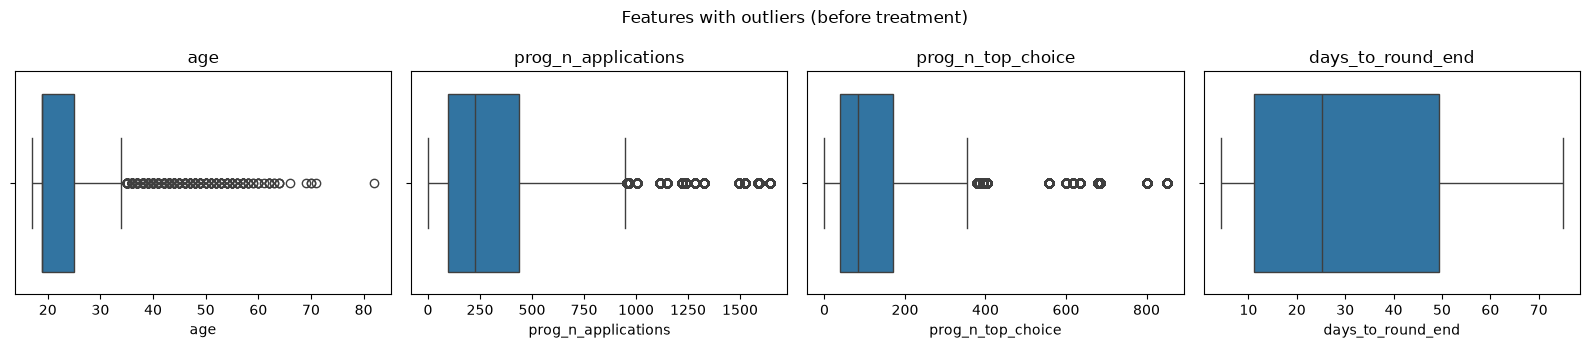

In [26]:
fig, axes = plt.subplots(1, 4, figsize=(16, 3.5))
for ax, col in zip(axes, ["age", "prog_n_applications", "prog_n_top_choice", "days_to_round_end"]):
    sns.boxplot(x=data[col], ax=ax, color="tab:blue")
    ax.set_title(col)
plt.suptitle("Features with outliers (before treatment)")
plt.tight_layout()
plt.show()

* `age` – applicants born in 1942 … 2008. Older applicants are real (adult learners), so they are not removed.
  values are clipped to the 1st–99th percentile so that a few very old applicants do not dominate the scale.
* `prog_n_applications`, `prog_n_top_choice` – strongly right-skewed (a few very popular programmes),
  a `log1p` transformation is applied.
* The other "outliers" are legitimate discrete values (e.g. priority 9, applicants with earlier invitations), they are kept.

age clipped to [18, 55]


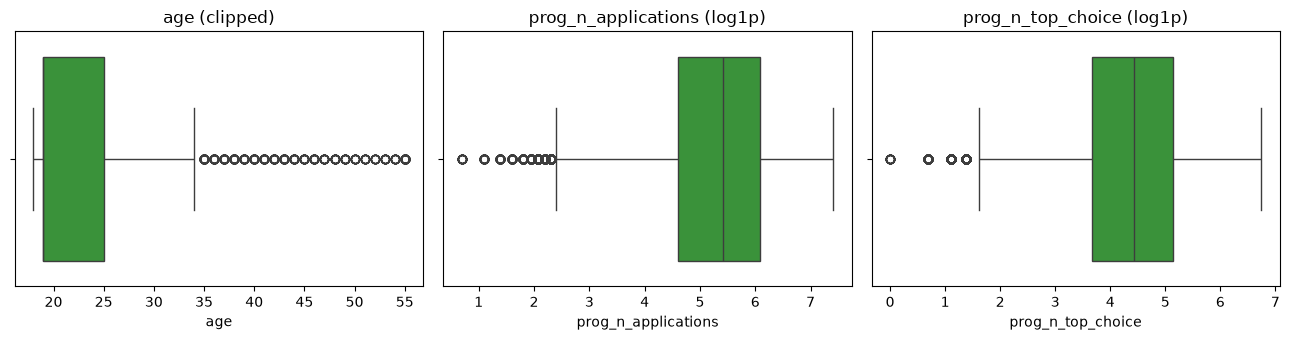

In [30]:
lo, hi = data["age"].quantile([0.01, 0.99])
data["age"] = data["age"].clip(lo, hi)
print(f"age clipped to [{lo:.0f}, {hi:.0f}]")
for col in ["prog_n_applications", "prog_n_top_choice"]:
    data[col] = np.log1p(data[col])

fig, axes = plt.subplots(1, 3, figsize=(13, 3.5))
for ax, col in zip(axes, ["age", "prog_n_applications", "prog_n_top_choice"]):
    sns.boxplot(x=data[col], ax=ax, color="tab:green")
    ax.set_title(col + (" (log1p)" if col != "age" else " (clipped)"))
plt.tight_layout()
plt.show()

## Exploratory data analysis

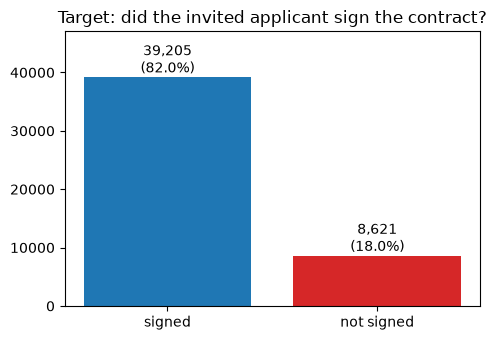

In [31]:
fig, ax = plt.subplots(figsize=(5, 3.5))
counts = data["ar_pasirase"].map({True: "signed", False: "not signed"}).value_counts()
ax.bar(counts.index, counts.values, color=["tab:blue", "tab:red"])
for i, v in enumerate(counts.values):
    ax.text(i, v, f"{v:,}\n({v / len(data):.1%})", ha="center", va="bottom")
ax.set_ylim(0, counts.max() * 1.2)
ax.set_title("Target: did the invited applicant sign the contract?")
plt.tight_layout()
plt.show()

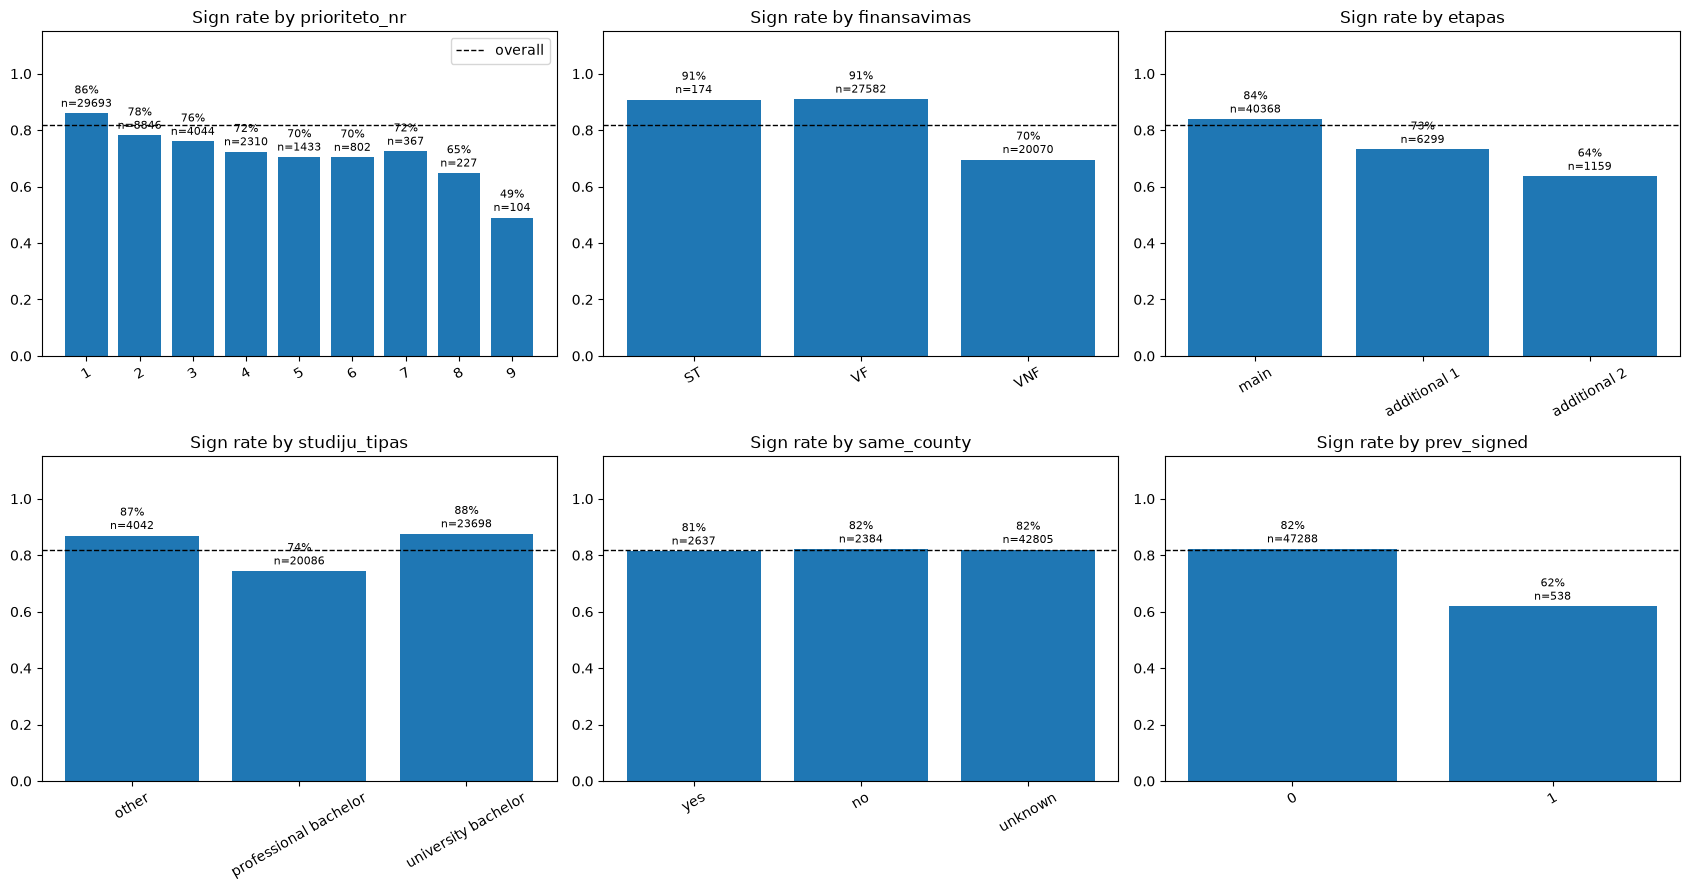

In [32]:
def sign_rate_plot(ax, col, order=None, min_n=30):
    t = data.groupby(col)["ar_pasirase"].agg(["mean", "size"])
    t = t[t["size"] >= min_n]
    if order is not None:
        t = t.reindex([o for o in order if o in t.index])
    ax.bar(t.index.astype(str), t["mean"], color="tab:blue")
    ax.axhline(data["ar_pasirase"].mean(), color="black", ls="--", lw=1, label="overall")
    for i, (m, n) in enumerate(zip(t["mean"], t["size"])):
        ax.text(i, m + 0.01, f"{m:.0%}\nn={n}", ha="center", va="bottom", fontsize=8)
    ax.set_ylim(0, 1.15)
    ax.set_title(f"Sign rate by {col}")
    ax.tick_params(axis="x", rotation=30)


fig, axes = plt.subplots(2, 3, figsize=(17, 9))
sign_rate_plot(axes[0, 0], "prioriteto_nr")
sign_rate_plot(axes[0, 1], "finansavimas")
sign_rate_plot(axes[0, 2], "etapas", order=["main", "additional 1", "additional 2"])
sign_rate_plot(axes[1, 0], "studiju_tipas")
sign_rate_plot(axes[1, 1], "same_county", order=["yes", "no", "unknown"])
sign_rate_plot(axes[1, 2], "prev_signed")
axes[0, 0].legend()
plt.tight_layout()
plt.show()

## Statistical check of hypotheses 1 and 2
Chi-square test of independence between each grouping and signing the contract.

In [35]:
def compare(label, hypothesis, mask_a, mask_b, name_a, name_b):
    a, b = data.loc[mask_a, "ar_pasirase"], data.loc[mask_b, "ar_pasirase"]
    table = [[a.sum(), (~a).sum()], [b.sum(), (~b).sum()]]
    chi2, p, _, _ = stats.chi2_contingency(table)
    return {"hypothesis": hypothesis, "comparison": label, "group A": name_a, "sign rate A": a.mean(), "n A": len(a),
            "group B": name_b, "sign rate B": b.mean(), "n B": len(b), "chi2": chi2, "p-value": p}


tests = pd.DataFrame([
    compare("priority", "H1", data["prioriteto_nr"] <= 2, data["prioriteto_nr"] >= 3, "1-2", "3-9"),
    compare("funding", "H1", data["finansavimas"] == "VF", data["finansavimas"] == "VNF", "VF", "VNF"),
    compare("round", "H2", data["etapas"] == "main", data["etapas"] != "main", "main", "additional"),
    compare("home municipality", "H2", data["same_municipality"] == "yes", data["same_municipality"] == "no",
            "same", "different"),
    compare("home county", "H2", data["same_county"] == "yes", data["same_county"] == "no", "same", "different"),
])
tests.style.format({"sign rate A": "{:.1%}", "sign rate B": "{:.1%}", "chi2": "{:.1f}", "p-value": "{:.2e}"})

,hypothesis,comparison,group A,sign rate A,n A,group B,sign rate B,n B,chi2,p-value
0,H1,priority,1-2,84.1%,38539,3-9,73.0%,9287,626.7,2.66e-138
1,H1,funding,VF,91.0%,27582,VNF,69.6%,20070,3590.3,0.00e+00
2,H2,round,main,83.9%,40368,additional,71.7%,7458,636.0,2.50e-140
3,H2,home municipality,same,82.3%,1635,different,81.6%,3386,0.3,5.78e-01
4,H2,home county,same,81.5%,2637,different,82.2%,2384,0.4,5.35e-01


### Exploratory data analysis

* **Target:** 82.0 % of invited applicants signed, 18.0 % did not – the imbalance is the same in both years (2024: 82.3 %, 2025: 81.6 %).
* **Priority (H1):** the sign rate falls steadily with the priority number: 86 % for priority 1 → 49 % for priority 9;
  priorities 1–2: 84.1 % vs. 3–9: 73.0 % (χ² = 627, p < 0.001).
* **Funding (H1):** the strongest single factor – state-funded places (VF) 91.0 % (ST also 91 %) vs. self-paid (VNF) 69.6 % (χ² = 3 590, p < 0.001).
* **Round (H2):** main round 83.9 % vs. additional rounds 71.7 % (64 % in the 2nd additional round of 2024), p < 0.001.
* **Home municipality / county (H2):** **no difference** – same municipality 82.3 % vs. different 81.6 % (p = 0.58),
  same county 81.5 % vs. 82.2 % (p = 0.53). This could only be checked on the 5 021 invitations with known residence.
* **Other patterns:** professional bachelor programmes (mostly colleges) 74 % vs. university bachelor 88 %;
  applicants who already signed in an earlier round of the same year sign the new invitation less often (62 %).
* No single feature separates the classes on its own, so the models need to combine many features.

### Preparing data for models

* **Target:** `not_signed` (1 = did not sign). The minority class is the positive class, so precision, recall and
  F1 describe how well the models find applicants who will **not** sign.
* **Split:** 60 % train / 20 % validation / 20 % test, stratified by the target and **grouped by applicant**
  (`StratifiedGroupKFold`), so the same person never appears in two parts. Validation is used for parameter
  analysis and early stopping, the test set only for the final evaluation.
* **Class imbalance:** `scale_pos_weight` (XGBoost) and `class_weight` (neural networks).
* **Encoding:** XGBoost and the MLP use the same matrix – one-hot encoding (categories with < 20 training rows grouped
  as "infrequent") + standard scaling of numeric features; the 2nd network uses learned embeddings for the
  high-cardinality categories. (XGBoost's native categorical support was also tried – see the XGBoost section.)

In [39]:
X = data[FEATURES].copy()
y = data["not_signed"].to_numpy()
groups = data["asmens_id"].to_numpy()

outer = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
trainval_idx, test_idx = next(outer.split(X, y, groups))
inner = StratifiedGroupKFold(n_splits=4, shuffle=True, random_state=RANDOM_STATE)
tr_rel, va_rel = next(inner.split(X.iloc[trainval_idx], y[trainval_idx], groups[trainval_idx]))
train_idx, val_idx = trainval_idx[tr_rel], trainval_idx[va_rel]

y_tr, y_va, y_te = y[train_idx], y[val_idx], y[test_idx]
for name, idx in [("train", train_idx), ("validation", val_idx), ("test", test_idx)]:
    print(f"{name:10s} {len(idx):>6,} rows | not signed: {y[idx].mean():.1%}")
assert not (set(groups[train_idx]) & set(groups[test_idx])) and not (set(groups[train_idx]) & set(groups[val_idx]))
print("No applicant appears in more than one part.")

train      28,695 rows | not signed: 18.0%
validation  9,566 rows | not signed: 18.0%
test        9,565 rows | not signed: 18.0%
No applicant appears in more than one part.


In [41]:
# ----- metrics used for all models (positive class = not signed) -----
def scores(y_true, proba, threshold=0.5):
    pred = (proba >= threshold).astype(int)
    return {"Accuracy": accuracy_score(y_true, pred),
            "Balanced acc.": balanced_accuracy_score(y_true, pred),
            "Precision": precision_score(y_true, pred, zero_division=0),
            "Recall": recall_score(y_true, pred, zero_division=0),
            "F1": f1_score(y_true, pred, zero_division=0),
            "ROC AUC": roc_auc_score(y_true, proba),
            "PR AUC": average_precision_score(y_true, proba)}


def score_table(probas, threshold=0.5):
    """probas: {'train': (y, p), 'test': (y, p), ...} -> DataFrame with one row per set"""
    return pd.DataFrame({k: scores(yt, p, threshold) for k, (yt, p) in probas.items()}).T.round(4)


def plot_confusions(probas, title, threshold=0.5):
    fig, axes = plt.subplots(1, len(probas), figsize=(5 * len(probas), 4))
    for ax, (name, (yt, p)) in zip(np.atleast_1d(axes), probas.items()):
        ConfusionMatrixDisplay(confusion_matrix(yt, (p >= threshold).astype(int)),
                               display_labels=["signed", "not signed"]).plot(ax=ax, cmap="Blues", colorbar=False,
                                                                             values_format=",")
        ax.set_title(f"{title} – {name}")
    plt.tight_layout()
    plt.show()


def plot_param_study(results, metrics=("Train AUC", "Val AUC", "Val F1"), log_params=(), ncols=3):
    params = list(dict.fromkeys(results["parameter"]))
    nrows = int(np.ceil(len(params) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(5.5 * ncols, 3.8 * nrows))
    for ax, param in zip(axes.ravel(), params):
        r = results[results["parameter"] == param]
        x = np.arange(len(r))
        for m, style in zip(metrics, ["o--", "o-", "s-"]):
            ax.plot(x, r[m], style, label=m)
        ax.set_xticks(x, r["value"], rotation=20)
        ax.set_title(param)
        ax.set_ylim(min(0.4, r[list(metrics)].min().min() - 0.02), 1.0)
    for ax in axes.ravel()[len(params):]:
        ax.axis("off")
    axes.ravel()[0].legend(loc="lower right")
    plt.tight_layout()
    plt.show()


# ----- baseline: always predict the majority class ("signed") -----
baseline_test = scores(y_te, np.zeros(len(y_te)))
pd.DataFrame({"Majority baseline (test)": baseline_test}).T.round(4)

,Accuracy,Balanced acc.,Precision,Recall,F1,ROC AUC,PR AUC
Majority baseline (test),0.8198,0.5,0.0,0.0,0.0,0.5,0.1802


In [43]:
# ----- matrices for XGBoost and the MLP: median imputation + scaling, one-hot (rare categories grouped) -----
onehot_prep = ColumnTransformer([
    ("num", Pipeline([("impute", SimpleImputer(strategy="median")), ("scale", StandardScaler())]), NUM_FEATURES),
    ("cat", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=20, sparse_output=False),
     CAT_LOW + CAT_HIGH),
])
Xo_tr = onehot_prep.fit_transform(X.iloc[train_idx]).astype("float32")
Xo_va = onehot_prep.transform(X.iloc[val_idx]).astype("float32")
Xo_te = onehot_prep.transform(X.iloc[test_idx]).astype("float32")
ONEHOT_NAMES = onehot_prep.get_feature_names_out()
print("Input dimension (XGBoost and MLP):", Xo_tr.shape[1])

# ----- matrices for the embedding network -----
dense_prep = ColumnTransformer([
    ("num", Pipeline([("impute", SimpleImputer(strategy="median")), ("scale", StandardScaler())]), NUM_FEATURES),
    ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CAT_LOW),
])
Xd_tr = dense_prep.fit_transform(X.iloc[train_idx]).astype("float32")
Xd_va = dense_prep.transform(X.iloc[val_idx]).astype("float32")
Xd_te = dense_prep.transform(X.iloc[test_idx]).astype("float32")

# integer codes for high-cardinality columns; 0 = unknown / rare (< 5 rows in train)
emb_vocab, emb_cardinality = {}, {}
for c in CAT_HIGH:
    vc = X.iloc[train_idx][c].value_counts()
    vocab = [v for v in vc[vc >= 5].index if v != "unknown"]
    emb_vocab[c] = {v: i + 1 for i, v in enumerate(vocab)}
    emb_cardinality[c] = len(vocab) + 1


def emb_inputs(idx, dense):
    d = {"dense_features": dense}
    for c in CAT_HIGH:
        d[c] = X.iloc[idx][c].map(emb_vocab[c]).fillna(0).astype("int32").to_numpy().reshape(-1, 1)
    return d


Xe_tr, Xe_va, Xe_te = emb_inputs(train_idx, Xd_tr), emb_inputs(val_idx, Xd_va), emb_inputs(test_idx, Xd_te)
print("Dense part:", Xd_tr.shape[1], "| embedding vocabularies:", emb_cardinality)

Input dimension (XGBoost and MLP): 585
Dense part: 68 | embedding vocabularies: {'programos_valst_kodas': 591, 'mokymo_istaiga': 29, 'asm_gyv_sav': 59}


# Machine learning algorithm (except neural network)

**XGBoost** (extreme gradient boosting) builds an ensemble of decision trees sequentially: each new tree is fitted to the
gradient of the loss of the current ensemble, and its contribution is shrunk by the learning rate. It handles missing
values natively and works well on tabular data of this size.

First a model with typical parameters is trained, then the influence of each parameter is analysed by changing one
parameter at a time (others fixed) and measuring ROC AUC on the train and validation sets and F1 on validation.
(`n_jobs=8`: on this 16-thread machine using all threads made training ~30× slower because of thread contention.)

In [45]:
NEG_POS = (y_tr == 0).sum() / (y_tr == 1).sum()
XGB_BASE = dict(n_estimators=300, max_depth=6, learning_rate=0.1, min_child_weight=1, subsample=1.0,
                colsample_bytree=1.0, scale_pos_weight=NEG_POS, tree_method="hist", importance_type="gain",
                eval_metric="auc", n_jobs=8, random_state=RANDOM_STATE)
print(f"scale_pos_weight = negatives / positives = {NEG_POS:.2f}")

t0 = time.perf_counter()
xgb_default = XGBClassifier(**XGB_BASE).fit(Xo_tr, y_tr)
print(f"Training time: {time.perf_counter() - t0:.1f} s")
score_table({"train": (y_tr, xgb_default.predict_proba(Xo_tr)[:, 1]),
             "validation": (y_va, xgb_default.predict_proba(Xo_va)[:, 1])})

scale_pos_weight = negatives / positives = 4.55
Training time: 2.4 s


,Accuracy,Balanced acc.,Precision,Recall,F1,ROC AUC,PR AUC
train,0.7676,0.8045,0.4281,0.8623,0.5722,0.8888,0.6692
validation,0.7138,0.7173,0.3556,0.7229,0.4767,0.7936,0.4709


## Encoding with categorical features

XGBoost can also split directly on categorical columns (`enable_categorical=True`, partition-based splits).
Both encodings are compared with the default parameters:

In [46]:
X_cat = X.copy()
for c in CAT_LOW + CAT_HIGH:
    X_cat[c] = pd.Categorical(X_cat[c].astype(str))
xgb_native = XGBClassifier(**XGB_BASE, enable_categorical=True, max_cat_to_onehot=1).fit(X_cat.iloc[train_idx], y_tr)
p_native = xgb_native.predict_proba(X_cat.iloc[val_idx])[:, 1]
pd.DataFrame({"one-hot encoding": scores(y_va, xgb_default.predict_proba(Xo_va)[:, 1]),
              "native categorical": scores(y_va, p_native)}).T.round(4)

,Accuracy,Balanced acc.,Precision,Recall,F1,ROC AUC,PR AUC
one-hot encoding,0.7138,0.7173,0.3556,0.7229,0.4767,0.7936,0.4709
native categorical,0.7591,0.6471,0.3688,0.4719,0.4140,0.7160,0.3964


Native categorical splits on the 650 programme codes over-fit badly (each split can group arbitrary programmes
together), so the one-hot matrix with rare categories grouped is used for XGBoost.

## Parameters influence

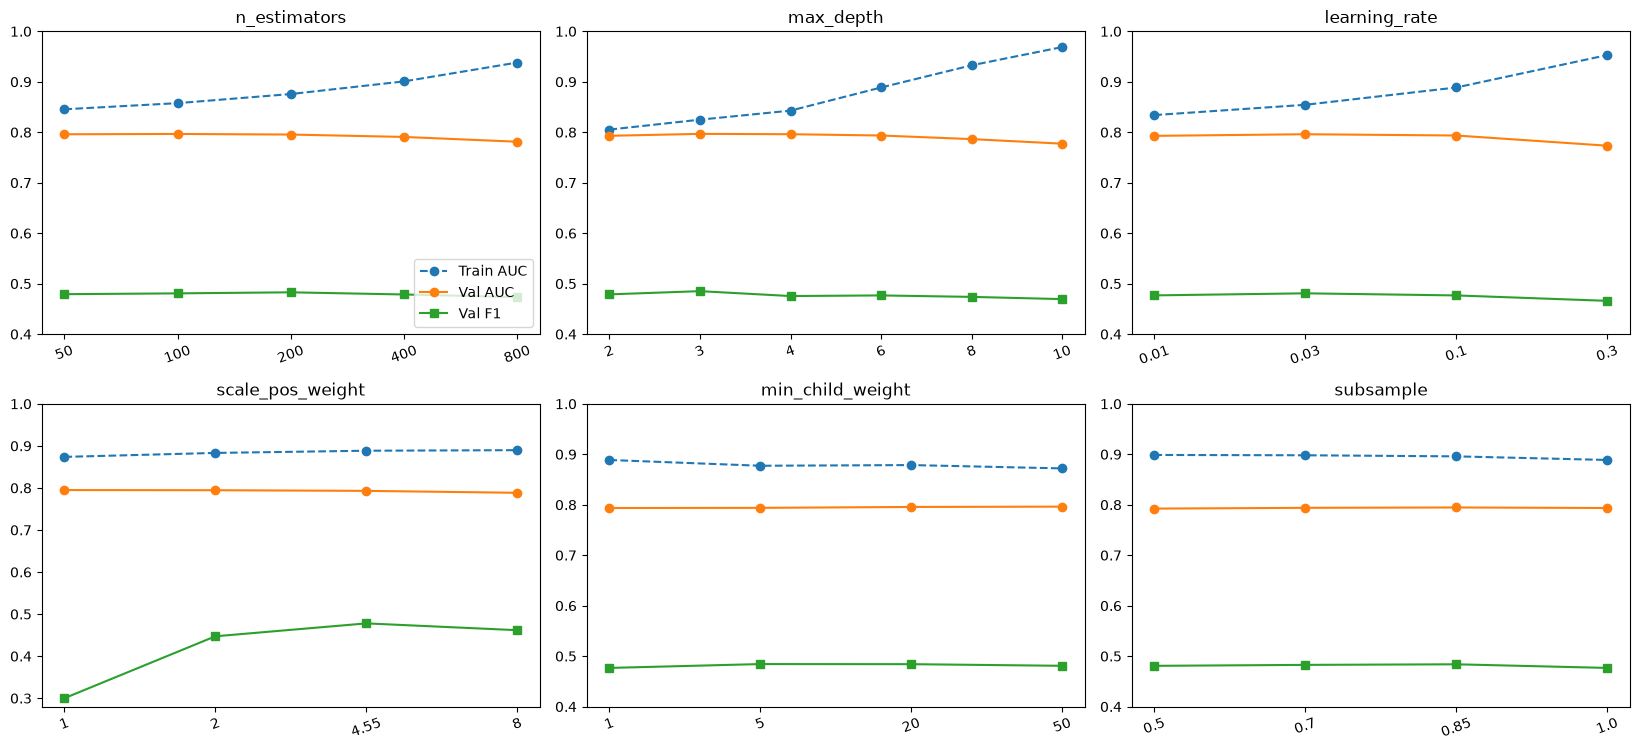

,parameter,value,Train AUC,Val AUC,Val F1,Val recall,time (s)
0,n_estimators,50,0.8455,0.7960,0.4791,0.7722,0.6438
1,n_estimators,100,0.8577,0.7966,0.4808,0.7606,0.7235
2,n_estimators,200,0.8758,0.7955,0.4828,0.7467,1.1613
3,n_estimators,400,0.9008,0.7907,0.4786,0.7148,1.7550
4,n_estimators,800,0.9382,0.7813,0.4734,0.6580,3.1922
5,max_depth,2,0.8053,0.7930,0.4788,0.7786,1.1646
6,max_depth,3,0.8249,0.7968,0.4851,0.7809,1.0109
7,max_depth,4,0.8429,0.7961,0.4755,0.7554,1.2124
8,max_depth,6,0.8888,0.7936,0.4767,0.7229,1.3983
9,max_depth,8,0.9327,0.7864,0.4738,0.6730,1.7933


In [47]:
xgb_space = {
    "n_estimators":     [50, 100, 200, 400, 800],
    "max_depth":        [2, 3, 4, 6, 8, 10],
    "learning_rate":    [0.01, 0.03, 0.1, 0.3],
    "scale_pos_weight": [1, 2, round(NEG_POS, 2), 8],
    "min_child_weight": [1, 5, 20, 50],
    "subsample":        [0.5, 0.7, 0.85, 1.0],
}

rows = []
for param, values in xgb_space.items():
    for v in values:
        t0 = time.perf_counter()
        m = XGBClassifier(**{**XGB_BASE, param: v}).fit(Xo_tr, y_tr)
        p_tr, p_va = m.predict_proba(Xo_tr)[:, 1], m.predict_proba(Xo_va)[:, 1]
        rows.append({"parameter": param, "value": str(v),
                     "Train AUC": roc_auc_score(y_tr, p_tr), "Val AUC": roc_auc_score(y_va, p_va),
                     "Val F1": f1_score(y_va, p_va >= 0.5), "Val recall": recall_score(y_va, p_va >= 0.5),
                     "time (s)": time.perf_counter() - t0})
xgb_study = pd.DataFrame(rows)
plot_param_study(xgb_study)
xgb_study.round(4)

**Observations from the parameter analysis:**
* `n_estimators`, `max_depth`, `learning_rate` control model complexity: train AUC rises to 0.94–0.97, but validation AUC
  is highest at ~100 trees, depth 3–4 and learning rate 0.03 and then **decreases** (0.797 → 0.773–0.781) – classic over-fitting.
  The default model (300 trees, depth 6, lr 0.1) already over-fits: train AUC 0.889 vs. validation 0.794.
* `scale_pos_weight` hardly changes AUC (the ranking of applicants) but strongly changes the predictions at threshold 0.5:
  without weighting the model finds only 20 % of non-signers (F1 = 0.30), with weight 4.55 (= negatives / positives)
  it finds 72 % (F1 = 0.48). Weight 8 increases recall further but precision drops, so F1 decreases.
* `min_child_weight` and `subsample` act as regularisation – they reduce the train–validation gap and give a small gain in validation AUC.
* Validation AUC stays in a narrow range (0.77–0.80) for all settings: the limiting factor is the information in the
  data, not the model.

## Grid search with cross-validation

Based on the curves above, a grid over the most influential parameters is searched with 3-fold cross-validation
grouped by applicant (scoring = ROC AUC) on the training set.

In [49]:
xgb_grid = {
    "max_depth": [3, 4, 5],
    "learning_rate": [0.03, 0.1],
    "n_estimators": [100, 300, 600],
    "min_child_weight": [5, 20, 50],
    "subsample": [0.8],
}
t0 = time.perf_counter()
grid = GridSearchCV(XGBClassifier(**XGB_BASE), xgb_grid, scoring="roc_auc",
                    cv=StratifiedGroupKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE), n_jobs=1)
grid.fit(Xo_tr, y_tr, groups=groups[train_idx])
print(f"{len(grid.cv_results_['params'])} combinations, {time.perf_counter() - t0:.0f} s")
print("Best parameters:", grid.best_params_)
print(f"Best CV ROC AUC: {grid.best_score_:.4f}")
(pd.DataFrame(grid.cv_results_)
   .sort_values("rank_test_score")[["params", "mean_test_score", "std_test_score", "mean_fit_time"]]
   .head(10))

54 combinations, 200 s
Best parameters: {'learning_rate': 0.03, 'max_depth': 5, 'min_child_weight': 50, 'n_estimators': 300, 'subsample': 0.8}
Best CV ROC AUC: 0.7951


,params,mean_test_score,std_test_score,mean_fit_time
25,"{'learning_rate': 0.03, 'max_depth': 5, 'min_c...",0.795069,0.002632,1.336014
19,"{'learning_rate': 0.03, 'max_depth': 5, 'min_c...",0.794790,0.002115,1.473394
17,"{'learning_rate': 0.03, 'max_depth': 4, 'min_c...",0.794789,0.002745,2.240309
11,"{'learning_rate': 0.03, 'max_depth': 4, 'min_c...",0.794628,0.002770,1.816014
26,"{'learning_rate': 0.03, 'max_depth': 5, 'min_c...",0.794547,0.002846,2.850175
22,"{'learning_rate': 0.03, 'max_depth': 5, 'min_c...",0.794541,0.003122,1.316682
14,"{'learning_rate': 0.03, 'max_depth': 4, 'min_c...",0.794303,0.003197,2.141234
20,"{'learning_rate': 0.03, 'max_depth': 5, 'min_c...",0.794089,0.002470,1.976444
10,"{'learning_rate': 0.03, 'max_depth': 4, 'min_c...",0.793954,0.002475,1.379265
13,"{'learning_rate': 0.03, 'max_depth': 4, 'min_c...",0.793875,0.002843,1.080553


## Model with best parameters

In [53]:
XGB_BEST = {**XGB_BASE, **grid.best_params_}
xgb_best = XGBClassifier(**XGB_BEST).fit(Xo_tr, y_tr)

p_xgb = {"train": (y_tr, xgb_best.predict_proba(Xo_tr)[:, 1]),
         "validation": (y_va, xgb_best.predict_proba(Xo_va)[:, 1]),
         "test": (y_te, xgb_best.predict_proba(Xo_te)[:, 1])}
xgb_scores = score_table(p_xgb)
xgb_scores

,Accuracy,Balanced acc.,Precision,Recall,F1,ROC AUC,PR AUC
train,0.7093,0.7506,0.3634,0.8152,0.5027,0.8275,0.5234
validation,0.6953,0.7314,0.3477,0.7878,0.4825,0.8001,0.4749
test,0.6948,0.7268,0.3457,0.7767,0.4785,0.7999,0.4606


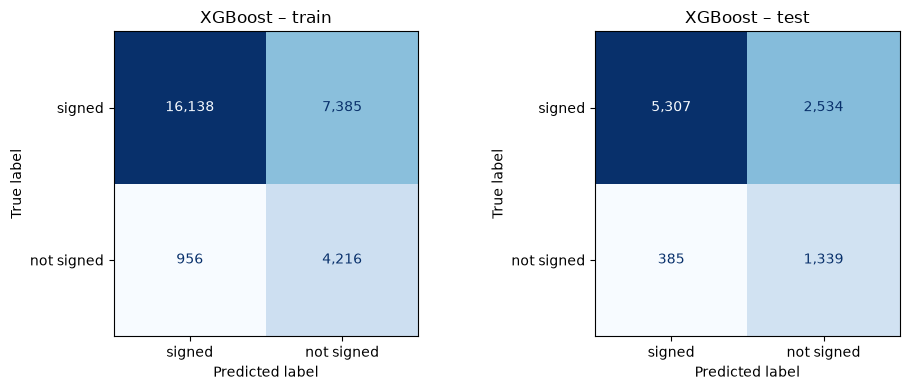

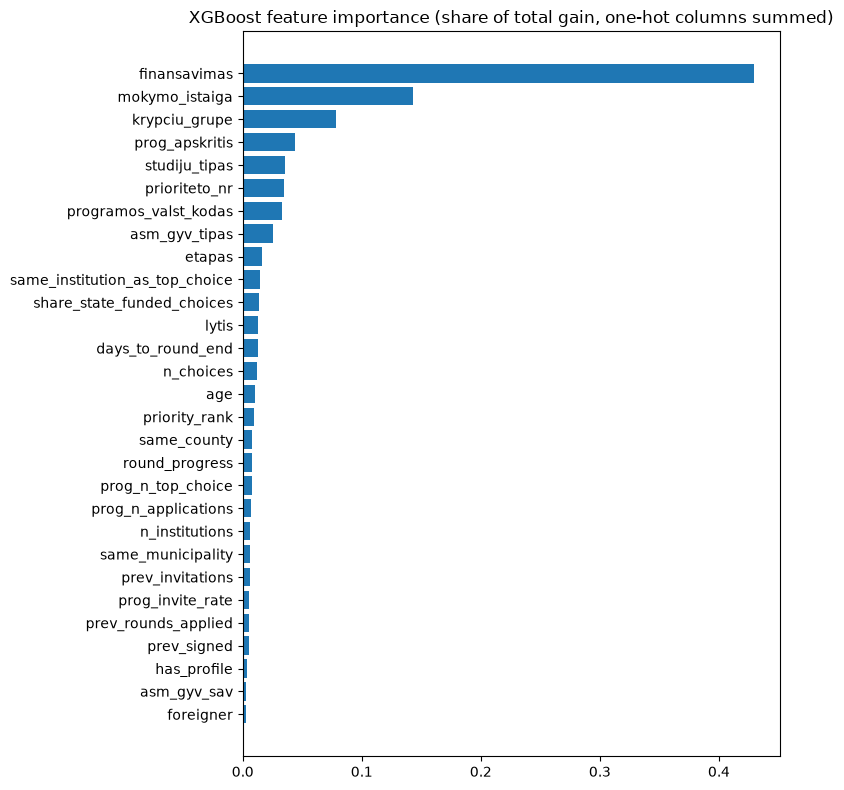

In [54]:
plot_confusions({k: p_xgb[k] for k in ["train", "test"]}, "XGBoost")

# gain importance of the one-hot columns is summed back to the original feature
def original_feature(name):
    kind, rest = name.split("__", 1)
    if kind == "num":
        return rest
    return max((c for c in CAT_LOW + CAT_HIGH if rest.startswith(c + "_")), key=len)


imp = (pd.Series(xgb_best.feature_importances_, index=[original_feature(n) for n in ONEHOT_NAMES])
         .groupby(level=0).sum().sort_values())
imp = imp / imp.sum()
fig, ax = plt.subplots(figsize=(8, 8))
ax.barh(imp.index, imp.values, color="tab:blue")
ax.set_title("XGBoost feature importance (share of total gain, one-hot columns summed)")
plt.tight_layout()
plt.show()

# 1st neural network

**Multilayer perceptron (MLP)** – a fully connected feed-forward network. Input: 16 scaled numeric features and
one-hot encoded categorical features (categories with < 20 training rows are grouped). Hidden layers with the same
number of neurons, dropout after each hidden layer, one sigmoid output neuron (probability of *not signing*).
Loss: binary cross-entropy with class weights. Training stops when validation ROC AUC has not improved for
6 epochs (early stopping, best weights restored).

Parameter analysis follows the practicals: starting from a default configuration, one parameter at a time is changed
(number of hidden layers, neurons, activation function, optimizer, dropout, learning rate, batch size).

In [55]:
CLASS_WEIGHT = {0: len(y_tr) / (2 * (y_tr == 0).sum()), 1: len(y_tr) / (2 * (y_tr == 1).sum())}
print("Class weights:", {k: round(v, 3) for k, v in CLASS_WEIGHT.items()})


def make_optimizer(name, lr):
    if name == "sgd":
        return keras.optimizers.SGD(learning_rate=lr, momentum=0.9)
    return {"rmsprop": keras.optimizers.RMSprop, "adam": keras.optimizers.Adam,
            "nadam": keras.optimizers.Nadam}[name](learning_rate=lr)


def build_mlp(n_layers=2, units=64, activation="relu", dropout=0.2, optimizer="adam", learning_rate=1e-3):
    keras.utils.set_random_seed(RANDOM_STATE)
    model = keras.Sequential([keras.Input(shape=(Xo_tr.shape[1],))])
    for _ in range(n_layers):
        model.add(layers.Dense(units, activation=activation))
        if dropout > 0:
            model.add(layers.Dropout(dropout))
    model.add(layers.Dense(1, activation="sigmoid"))
    model.compile(optimizer=make_optimizer(optimizer, learning_rate), loss="binary_crossentropy",
                  metrics=[keras.metrics.AUC(name="auc")])
    return model


def fit_nn(model, X_train, y_train, X_val, y_val, batch_size=256, epochs=60, patience=6):
    early = keras.callbacks.EarlyStopping(monitor="val_auc", mode="max", patience=patience, restore_best_weights=True)
    return model.fit(X_train, y_train, validation_data=(X_val, y_val), epochs=epochs, batch_size=batch_size,
                     class_weight=CLASS_WEIGHT, callbacks=[early], verbose=0)


def predict(model, X_):
    return model.predict(X_, batch_size=4096, verbose=0).ravel()


def nn_param_study(build_fn, default, space, X_train, X_val):
    rows = []
    for param, values in space.items():
        for v in values:
            cfg = {**default, param: v}
            batch_size = cfg.pop("batch_size")
            t0 = time.perf_counter()
            model = build_fn(**cfg)
            hist = fit_nn(model, X_train, y_tr, X_val, y_va, batch_size=batch_size)
            p_tr, p_va = predict(model, X_train), predict(model, X_val)
            rows.append({"parameter": param, "value": str(v), "raw": v,
                         "Train AUC": roc_auc_score(y_tr, p_tr), "Val AUC": roc_auc_score(y_va, p_va),
                         "Val F1": f1_score(y_va, p_va >= 0.5), "epochs": len(hist.history["loss"]),
                         "time (s)": time.perf_counter() - t0})
    return pd.DataFrame(rows)


def best_values(study, default):
    """For every parameter take the value with the highest validation ROC AUC."""
    best = dict(default)
    for param, r in study.groupby("parameter", sort=False):
        best[param] = r.loc[r["Val AUC"].idxmax(), "raw"]
    return best


def plot_history(hist, title):
    h = hist.history
    fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
    axes[0].plot(h["loss"], label="train"); axes[0].plot(h["val_loss"], label="validation")
    axes[0].set_title(f"{title}: loss"); axes[0].set_xlabel("epoch"); axes[0].legend()
    axes[1].plot(h["auc"], label="train"); axes[1].plot(h["val_auc"], label="validation")
    axes[1].set_title(f"{title}: ROC AUC"); axes[1].set_xlabel("epoch"); axes[1].legend()
    plt.tight_layout()
    plt.show()

Class weights: {0: np.float64(0.61), 1: np.float64(2.774)}


W0000 00:00:1795015908.534808  932263 cuda_executor.cc:1710] Failed to determine cuDNN version (Note that this is expected if the application doesn't link the cuDNN plugin): INTERNAL: cuDNN error: CUDNN_STATUS_INTERNAL_ERROR
=== Source Location Trace: === 
external/xla/xla/stream_executor/cuda/cudnn_api_wrappers.cc:77
external/xla/xla/stream_executor/cuda/cudnn_api_wrappers.cc:107
external/xla/xla/stream_executor/cuda/cudnn_api_wrappers.cc:112

W0000 00:00:1795015908.904901  912855 dlopen_checker.cc:38] Could not load dynamic library 'libcudnn.so.9'; dlerror: libcudnn.so.9: cannot open shared object file: No such file or directory
W0000 00:00:1795015908.904944  912855 gpu_device.cc:2359] Cannot dlopen some GPU libraries. Please make sure the missing libraries mentioned above are installed properly if you would like to use GPU. Follow the guide at https://www.tensorflow.org/install/gpu for how to download and setup the required libraries for your platform.
Skipping registering GPU devic

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │        37,504 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 41,729 (163.00 KB)

 Trainable params: 41,729 (163.00 KB)

 Non-trainable params: 0 (0.00 B)

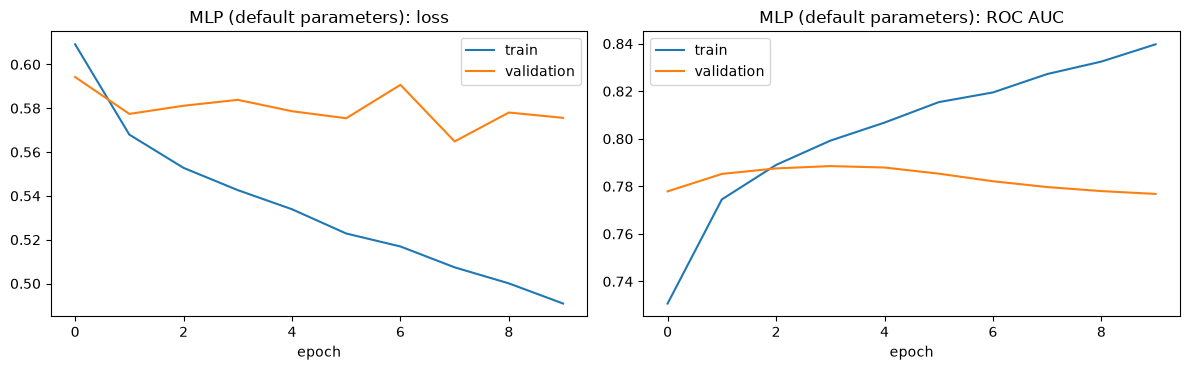

,Accuracy,Balanced acc.,Precision,Recall,F1,ROC AUC,PR AUC
train,0.6904,0.7412,0.3479,0.8208,0.4886,0.8199,0.5025
validation,0.6770,0.7216,0.3333,0.7913,0.4691,0.7885,0.4586


In [56]:
MLP_DEFAULT = dict(n_layers=2, units=64, activation="relu", dropout=0.2, optimizer="adam",
                   learning_rate=1e-3, batch_size=256)

cfg = dict(MLP_DEFAULT)
bs = cfg.pop("batch_size")
mlp_default = build_mlp(**cfg)
mlp_default.summary()
hist = fit_nn(mlp_default, Xo_tr, y_tr, Xo_va, y_va, batch_size=bs)
plot_history(hist, "MLP (default parameters)")
score_table({"train": (y_tr, predict(mlp_default, Xo_tr)), "validation": (y_va, predict(mlp_default, Xo_va))})

## Influence of parameters

30 models trained in 331 s


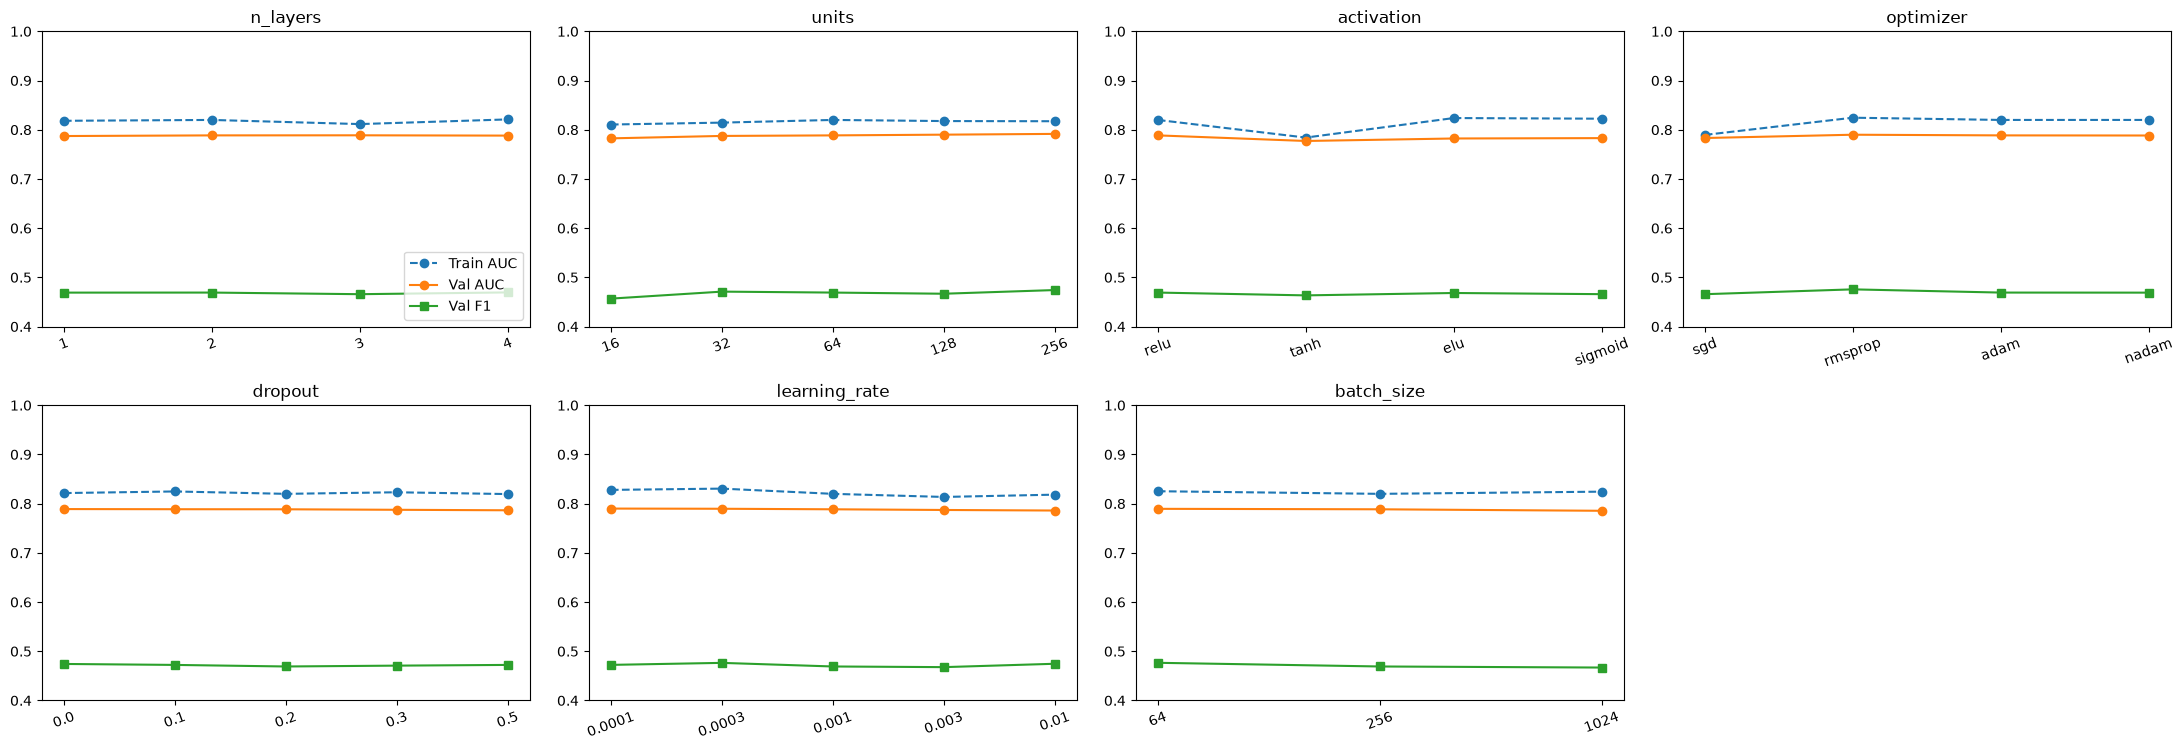

,parameter,value,Train AUC,Val AUC,Val F1,epochs,time (s)
0,n_layers,1,0.8182,0.7872,0.4690,11,7.1080
1,n_layers,2,0.8199,0.7885,0.4691,10,7.3429
2,n_layers,3,0.8115,0.7887,0.4658,9,7.5641
3,n_layers,4,0.8210,0.7881,0.4694,10,8.7970
4,units,16,0.8106,0.7825,0.4568,13,7.2990
5,units,32,0.8145,0.7874,0.4710,11,7.4175
6,units,64,0.8199,0.7885,0.4691,10,7.5096
7,units,128,0.8176,0.7900,0.4667,9,9.0037
8,units,256,0.8173,0.7916,0.4742,8,11.6916
9,activation,relu,0.8199,0.7885,0.4691,10,7.2922


In [57]:
mlp_space = {
    "n_layers":      [1, 2, 3, 4],
    "units":         [16, 32, 64, 128, 256],
    "activation":    ["relu", "tanh", "elu", "sigmoid"],
    "optimizer":     ["sgd", "rmsprop", "adam", "nadam"],
    "dropout":       [0.0, 0.1, 0.2, 0.3, 0.5],
    "learning_rate": [1e-4, 3e-4, 1e-3, 3e-3, 1e-2],
    "batch_size":    [64, 256, 1024],
}
t0 = time.perf_counter()
mlp_study = nn_param_study(build_mlp, MLP_DEFAULT, mlp_space, Xo_tr, Xo_va)
print(f"{len(mlp_study)} models trained in {time.perf_counter() - t0:.0f} s")
plot_param_study(mlp_study, ncols=4)
mlp_study.drop(columns="raw").round(4)

* All 30 configurations reach validation AUC 0.777–0.792 – the MLP is not very sensitive to its architecture, which again
  shows that the information in the features, not model capacity, limits the accuracy.
* **Layers:** 1–4 hidden layers give practically the same result (0.787–0.789). **Neurons:** wider layers are slightly
  better (16 → 256 neurons: 0.783 → 0.792).
* **Activation:** ReLU is best; tanh is the worst (0.777); sigmoid and ELU need many more epochs (60 and 27 vs. 10) –
  sigmoid suffers from vanishing gradients.
* **Optimizer:** RMSprop ≈ Adam ≈ Nadam (0.788–0.790); SGD with momentum learns much more slowly (stopped at the 60-epoch limit) and is worse.
* **Dropout** has little effect, because early stopping already prevents over-fitting (training stops after ~10 epochs).
* **Learning rate:** a smaller rate (1e-4) is slightly better but needs 4× more epochs; a large rate (1e-2) converges quickly to a worse solution.
* **Batch size:** 64 is slightly better than 1 024 but training takes twice as long.

## Model with best parameters

Best value of every parameter: {'n_layers': 3, 'units': 256, 'activation': 'relu', 'dropout': 0.0, 'optimizer': 'rmsprop', 'learning_rate': 0.0001, 'batch_size': 64}
Validation AUC: combined best = 0.7917, default = 0.7885
-> the combined configuration is used


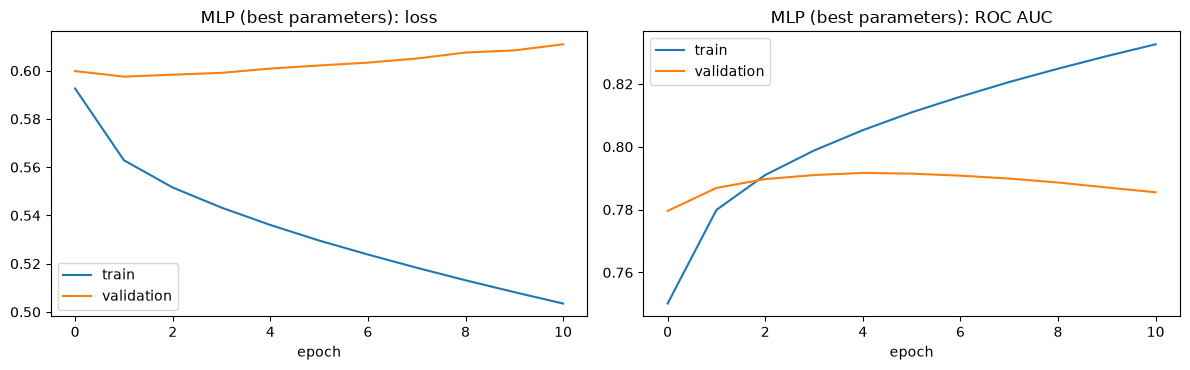

,Accuracy,Balanced acc.,Precision,Recall,F1,ROC AUC,PR AUC
train,0.6847,0.7381,0.3434,0.8215,0.4843,0.8159,0.5021
validation,0.6707,0.7205,0.3295,0.7983,0.4665,0.7917,0.4594
test,0.6737,0.7186,0.3303,0.7889,0.4657,0.7909,0.4435


In [58]:
MLP_BEST = best_values(mlp_study, MLP_DEFAULT)
print("Best value of every parameter:", MLP_BEST)

cfg = dict(MLP_BEST)
bs = cfg.pop("batch_size")
mlp_best = build_mlp(**cfg)
hist = fit_nn(mlp_best, Xo_tr, y_tr, Xo_va, y_va, batch_size=bs)

# combining individually best values does not always give the best model -> keep the better one on validation
auc_combined = roc_auc_score(y_va, predict(mlp_best, Xo_va))
auc_default = roc_auc_score(y_va, predict(mlp_default, Xo_va))
print(f"Validation AUC: combined best = {auc_combined:.4f}, default = {auc_default:.4f}")
if auc_default > auc_combined:
    print("-> the default configuration is kept")
    mlp_best, MLP_BEST = mlp_default, MLP_DEFAULT
else:
    print("-> the combined configuration is used")
    plot_history(hist, "MLP (best parameters)")

p_mlp = {"train": (y_tr, predict(mlp_best, Xo_tr)),
         "validation": (y_va, predict(mlp_best, Xo_va)),
         "test": (y_te, predict(mlp_best, Xo_te))}
mlp_scores = score_table(p_mlp)
mlp_scores

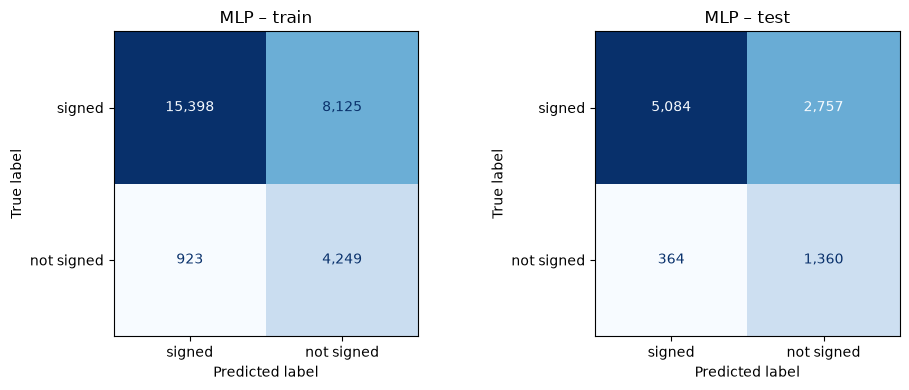

In [59]:
plot_confusions({k: p_mlp[k] for k in ["train", "test"]}, "MLP")

# 2nd network

**MLP with embedding layers (entity embeddings).** One-hot encoding of the 650 programme codes, 29 institutions
and 60 municipalities produces a large and sparse input, and similar programmes are not related to each other.
In this network each high-cardinality category (`programos_valst_kodas`, `mokymo_istaiga`, `asm_gyv_sav`) is
mapped to a short dense vector that is **learned** during training (Keras `Embedding` layer). The embeddings are
concatenated with the numeric and low-cardinality one-hot features and passed to fully connected layers.
Built with the Keras functional API (multiple inputs).

Parameters analysed: embedding size, hidden layer architecture, dropout, L2 regularisation of the embeddings,
learning rate.

Model: "functional_161"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ programos_valst_ko… │ (None, 1)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ mokymo_istaiga      │ (None, 1)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ asm_gyv_sav         │ (None, 1)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ emb_programos_vals… │ (None, 1, 8)      │      4,728 │ programos_valst_… │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ emb_mokymo_istaiga  │ (None, 1, 8)      │        232 │ mokymo_istaiga[0… │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ emb_asm_gyv_sav     │ (None, 1, 8)      │        472 │ asm_gyv_sav[0][0] │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_features      │ (None, 68)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ flatten (Flatten)   │ (None, 8)         │          0 │ emb_programos_va… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ flatten_1 (Flatten) │ (None, 8)         │          0 │ emb_mokymo_istai… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ flatten_2 (Flatten) │ (None, 8)         │          0 │ emb_asm_gyv_sav[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate         │ (None, 92)        │          0 │ dense_features[0… │
│ (Concatenate)       │                   │            │ flatten[0][0],    │
│                     │                   │            │ flatten_1[0][0],  │
│                     │                   │            │ flatten_2[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_99 (Dense)    │ (None, 128)       │     11,904 │ concatenate[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_62          │ (None, 128)       │          0 │ dense_99[0][0]    │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_100 (Dense)   │ (None, 64)        │      8,256 │ dropout_62[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_63          │ (None, 64)        │          0 │ dense_100[0][0]   │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_101 (Dense)   │ (None, 1)         │         65 │ dropout_63[0][0]  │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 25,657 (100.22 KB)

 Trainable params: 25,657 (100.22 KB)

 Non-trainable params: 0 (0.00 B)

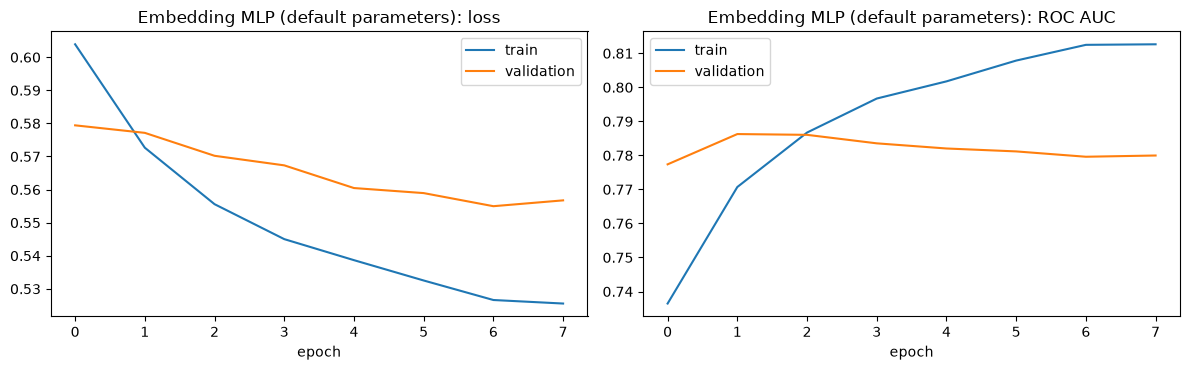

,Accuracy,Balanced acc.,Precision,Recall,F1,ROC AUC,PR AUC
train,0.6832,0.7271,0.3387,0.7958,0.4752,0.7976,0.4578
validation,0.6767,0.7191,0.3323,0.7855,0.4670,0.7863,0.4368


In [60]:
def build_embedding_mlp(emb_dim=8, hidden=(128, 64), dropout=0.2, l2_emb=1e-5, learning_rate=1e-3):
    keras.utils.set_random_seed(RANDOM_STATE)
    dense_in = keras.Input(shape=(Xd_tr.shape[1],), name="dense_features")
    inputs, parts = [dense_in], [dense_in]
    for c in CAT_HIGH:
        inp = keras.Input(shape=(1,), dtype="int32", name=c)
        reg = keras.regularizers.l2(l2_emb) if l2_emb else None
        emb = layers.Embedding(emb_cardinality[c], min(emb_dim, emb_cardinality[c]),
                               embeddings_regularizer=reg, name=f"emb_{c}")(inp)
        inputs.append(inp)
        parts.append(layers.Flatten()(emb))
    x = layers.Concatenate()(parts)
    for units in hidden:
        x = layers.Dense(units, activation="relu")(x)
        if dropout > 0:
            x = layers.Dropout(dropout)(x)
    out = layers.Dense(1, activation="sigmoid")(x)
    model = keras.Model(inputs, out)
    model.compile(optimizer=keras.optimizers.Adam(learning_rate), loss="binary_crossentropy",
                  metrics=[keras.metrics.AUC(name="auc")])
    return model


EMB_DEFAULT = dict(emb_dim=8, hidden=(128, 64), dropout=0.2, l2_emb=1e-5, learning_rate=1e-3, batch_size=256)
cfg = dict(EMB_DEFAULT)
bs = cfg.pop("batch_size")
emb_default = build_embedding_mlp(**cfg)
emb_default.summary()
hist = fit_nn(emb_default, Xe_tr, y_tr, Xe_va, y_va, batch_size=bs)
plot_history(hist, "Embedding MLP (default parameters)")
score_table({"train": (y_tr, predict(emb_default, Xe_tr)), "validation": (y_va, predict(emb_default, Xe_va))})

## Influence of parameters

19 models trained in 144 s


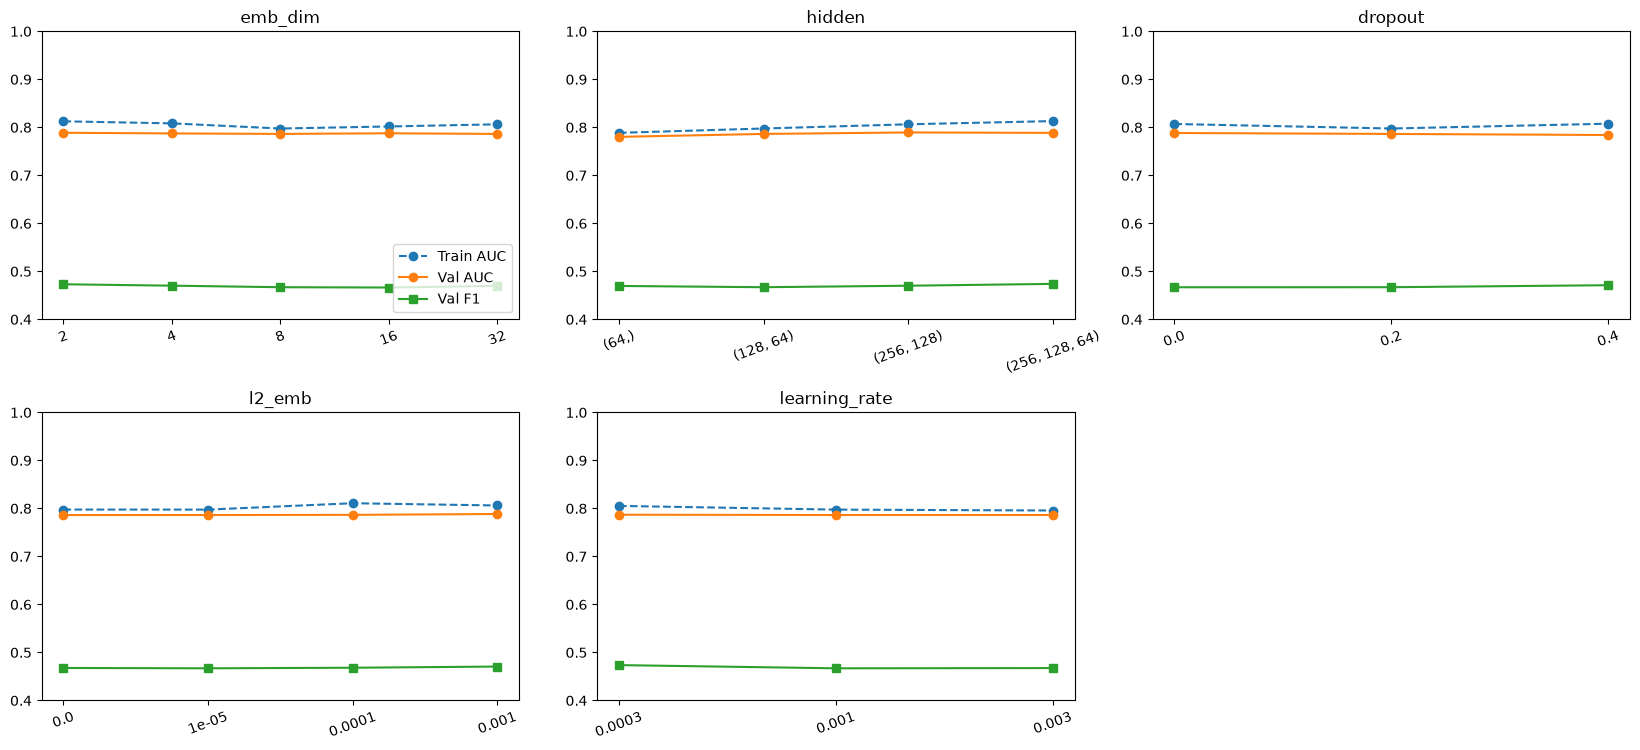

,parameter,value,Train AUC,Val AUC,Val F1,epochs,time (s)
0,emb_dim,2,0.8126,0.7887,0.4731,10,7.9451
1,emb_dim,4,0.8083,0.7874,0.4702,9,7.7500
2,emb_dim,8,0.7976,0.7863,0.4670,8,6.9141
3,emb_dim,16,0.8018,0.7877,0.4664,8,8.1461
4,emb_dim,32,0.8063,0.7863,0.4698,8,7.3419
5,hidden,"(64,)",0.7886,0.7802,0.4696,8,5.6946
6,hidden,"(128, 64)",0.7976,0.7863,0.4670,8,6.8006
7,hidden,"(256, 128)",0.8064,0.7894,0.4701,8,8.5099
8,hidden,"(256, 128, 64)",0.8130,0.7885,0.4740,9,10.0720
9,dropout,0.0,0.8070,0.7883,0.4669,8,5.8584


In [61]:
emb_space = {
    "emb_dim":       [2, 4, 8, 16, 32],
    "hidden":        [(64,), (128, 64), (256, 128), (256, 128, 64)],
    "dropout":       [0.0, 0.2, 0.4],
    "l2_emb":        [0.0, 1e-5, 1e-4, 1e-3],
    "learning_rate": [3e-4, 1e-3, 3e-3],
}
t0 = time.perf_counter()
emb_study = nn_param_study(build_embedding_mlp, EMB_DEFAULT, emb_space, Xe_tr, Xe_va)
print(f"{len(emb_study)} models trained in {time.perf_counter() - t0:.0f} s")
plot_param_study(emb_study)
emb_study.drop(columns="raw").round(4)

* **Embedding size:** the smallest size (2) is the best (0.789); larger embeddings do not help. The identity of the
  programme adds little beyond the features already describing it (popularity, field group, study type, institution, county).
* **Hidden layers:** wider networks are better – (256, 128) 0.789 vs. a single layer of 64 neurons 0.780.
* **Dropout:** no dropout is best, 0.4 is the worst (early stopping already regularises).
* **L2 regularisation of the embeddings:** the strongest value (1e-3) is slightly best – it stops the network from
  memorising rare programmes.
* **Learning rate:** 3e-4 is slightly better than 1e-3 and 3e-3.
* As with the 1st network, all settings are within a narrow range (0.780–0.789).

## Model with best parameters

Best value of every parameter: {'emb_dim': 2, 'hidden': (256, 128), 'dropout': 0.0, 'l2_emb': 0.001, 'learning_rate': 0.0003, 'batch_size': 256}
Validation AUC: combined best = 0.7921, default = 0.7863
-> the combined configuration is used


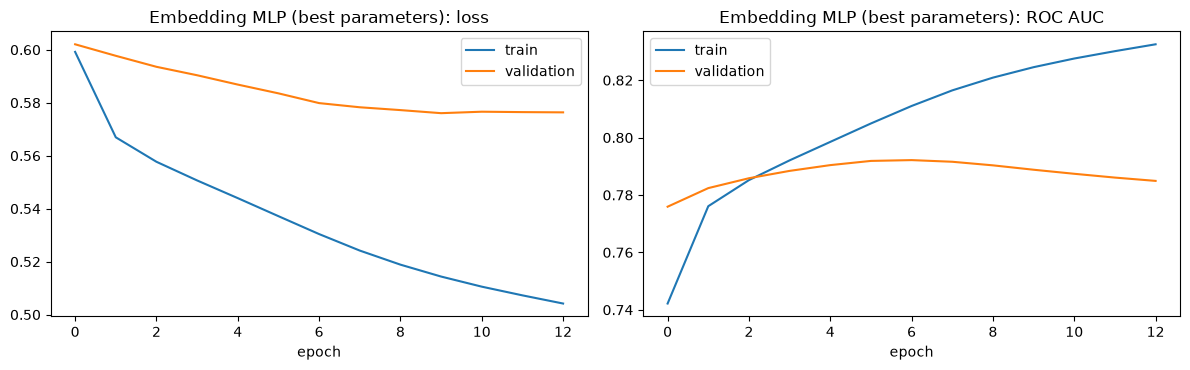

,Accuracy,Balanced acc.,Precision,Recall,F1,ROC AUC,PR AUC
train,0.6983,0.7430,0.3535,0.8130,0.4927,0.8205,0.5041
validation,0.6884,0.7296,0.3428,0.7942,0.4789,0.7921,0.4478
test,0.6864,0.7239,0.3395,0.7825,0.4735,0.7922,0.4432


In [62]:
EMB_BEST = best_values(emb_study, EMB_DEFAULT)
print("Best value of every parameter:", EMB_BEST)

cfg = dict(EMB_BEST)
bs = cfg.pop("batch_size")
emb_best = build_embedding_mlp(**cfg)
hist = fit_nn(emb_best, Xe_tr, y_tr, Xe_va, y_va, batch_size=bs)

auc_combined = roc_auc_score(y_va, predict(emb_best, Xe_va))
auc_default = roc_auc_score(y_va, predict(emb_default, Xe_va))
print(f"Validation AUC: combined best = {auc_combined:.4f}, default = {auc_default:.4f}")
if auc_default > auc_combined:
    print("-> the default configuration is kept")
    emb_best, EMB_BEST = emb_default, EMB_DEFAULT
else:
    print("-> the combined configuration is used")
    plot_history(hist, "Embedding MLP (best parameters)")

p_emb = {"train": (y_tr, predict(emb_best, Xe_tr)),
         "validation": (y_va, predict(emb_best, Xe_va)),
         "test": (y_te, predict(emb_best, Xe_te))}
emb_scores = score_table(p_emb)
emb_scores

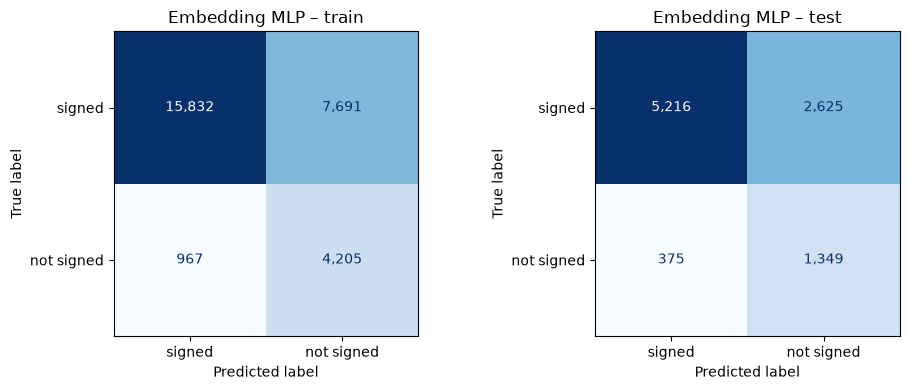

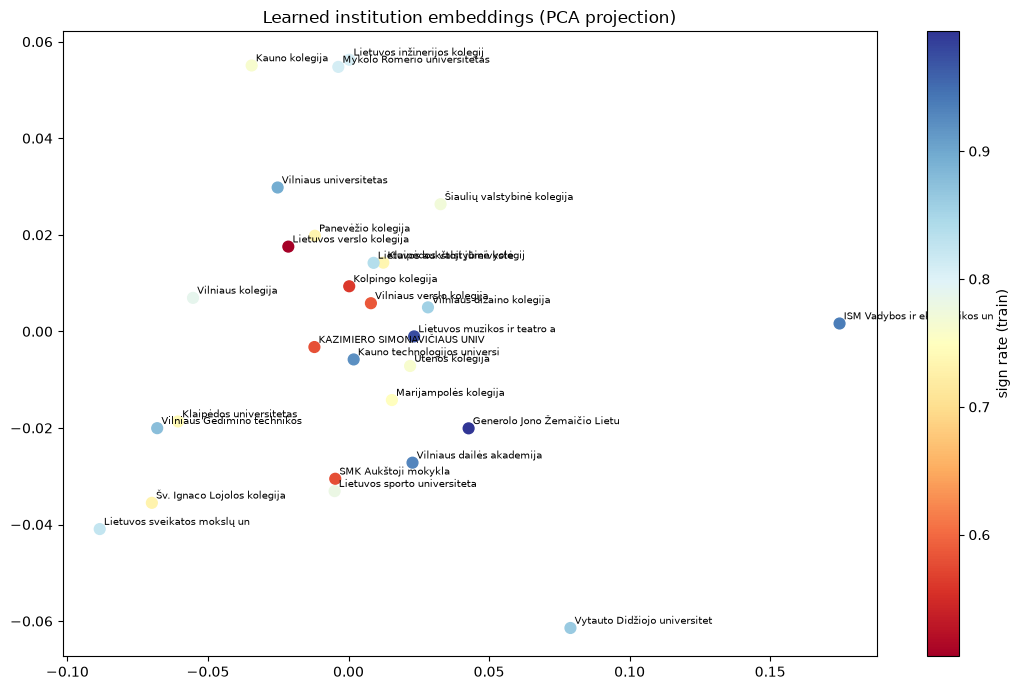

In [65]:
plot_confusions({k: p_emb[k] for k in ["train", "test"]}, "Embedding MLP")

# What did the network learn about institutions? 2-D PCA projection of the institution embeddings,
# coloured by the sign rate of the institution in the training data.
W = emb_best.get_layer("emb_mokymo_istaiga").get_weights()[0]
names = ["(rare / unknown)"] + list(emb_vocab["mokymo_istaiga"])
rate = data.iloc[train_idx].groupby("mokymo_istaiga")["ar_pasirase"].mean()
xy = PCA(n_components=2).fit_transform(W) if W.shape[1] > 1 else np.c_[W, np.zeros(len(W))]
fig, ax = plt.subplots(figsize=(11, 7))
sc = ax.scatter(xy[1:, 0], xy[1:, 1], c=[rate.get(n, np.nan) for n in names[1:]], cmap="RdYlBu", s=60)
for (px, py), n in zip(xy[1:], names[1:]):
    ax.annotate(n.replace("Viešoji įstaiga ", "").replace('"', "")[:28], (px, py), fontsize=7,
                xytext=(3, 3), textcoords="offset points")
plt.colorbar(sc, label="sign rate (train)")
ax.set_title("Learned institution embeddings (PCA projection)")
plt.tight_layout()
plt.show()

# Comparison of the best models

In [66]:
models = {"Majority baseline": {"train": (y_tr, np.zeros(len(y_tr))), "validation": (y_va, np.zeros(len(y_va))),
                                "test": (y_te, np.zeros(len(y_te)))},
          "XGBoost": p_xgb, "MLP (one-hot)": p_mlp, "MLP + embeddings": p_emb}

rows = []
for name, p in models.items():
    for part in ["train", "test"]:
        rows.append({"Model": name, "Set": part, **scores(*p[part])})
comparison = pd.DataFrame(rows).set_index(["Model", "Set"])
comparison["Error (1 - acc.)"] = 1 - comparison["Accuracy"]
comparison.round(4)

Accuracy  Balanced acc.  Precision  Recall      F1  \
Model             Set                                                         
Majority baseline train    0.8198         0.5000     0.0000  0.0000  0.0000   
                  test     0.8198         0.5000     0.0000  0.0000  0.0000   
XGBoost           train    0.7093         0.7506     0.3634  0.8152  0.5027   
                  test     0.6948         0.7268     0.3457  0.7767  0.4785   
MLP (one-hot)     train    0.6847         0.7381     0.3434  0.8215  0.4843   
                  test     0.6737         0.7186     0.3303  0.7889  0.4657   
MLP + embeddings  train    0.6983         0.7430     0.3535  0.8130  0.4927   
                  test     0.6864         0.7239     0.3395  0.7825  0.4735   

                         ROC AUC  PR AUC  Error (1 - acc.)  
Model             Set                                       
Majority baseline train   0.5000  0.1802            0.1802  
                  test    0.5000  0.1802            0.1802  
XGBoost           train   0.8275  0.5234            0.2907  
                  test    0.7999  0.4606            0.3052  
MLP (one-hot)     train   0.8159  0.5021            0.3153  
                  test    0.7909  0.4435            0.3263  
MLP + embeddings  train   0.8205  0.5041            0.3017  
                  test    0.7922  0.4432            0.3136

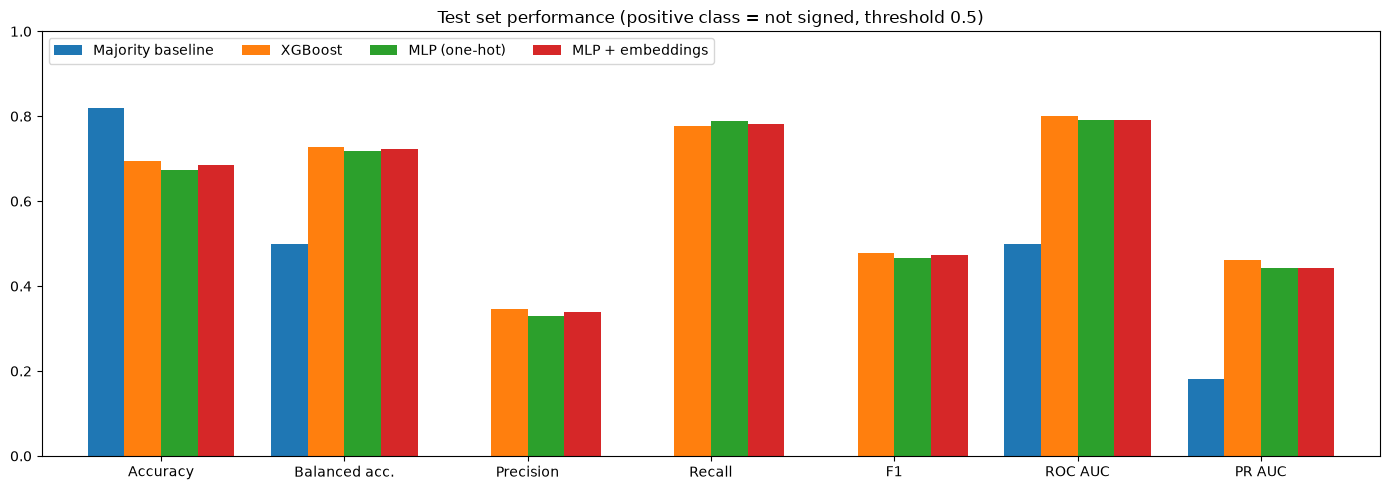

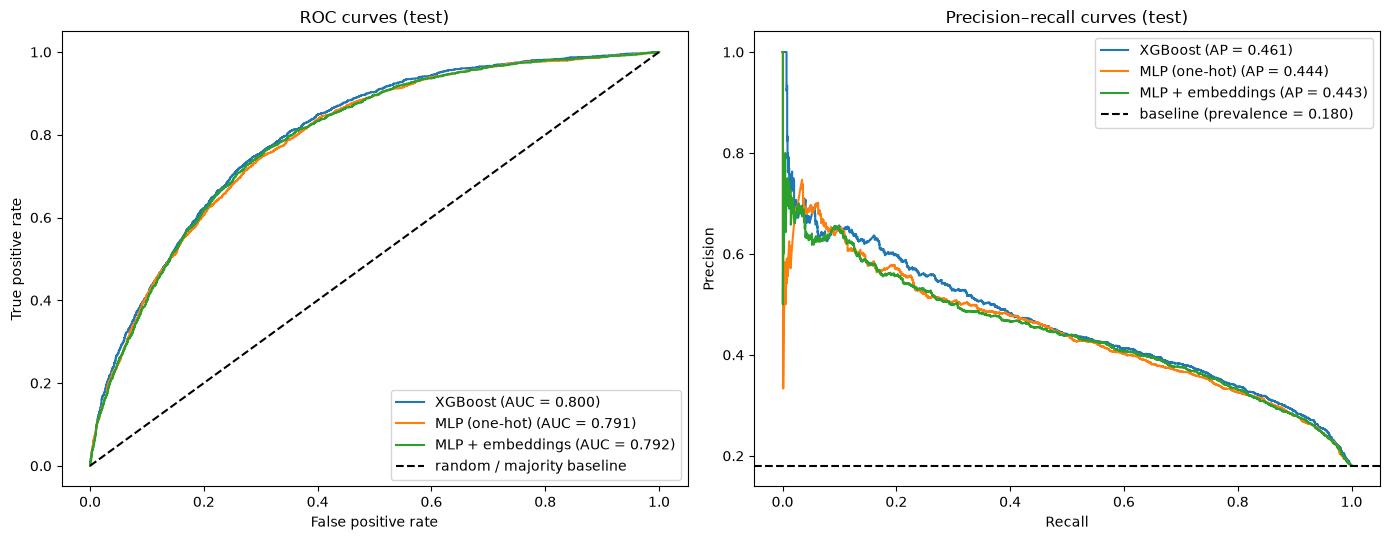

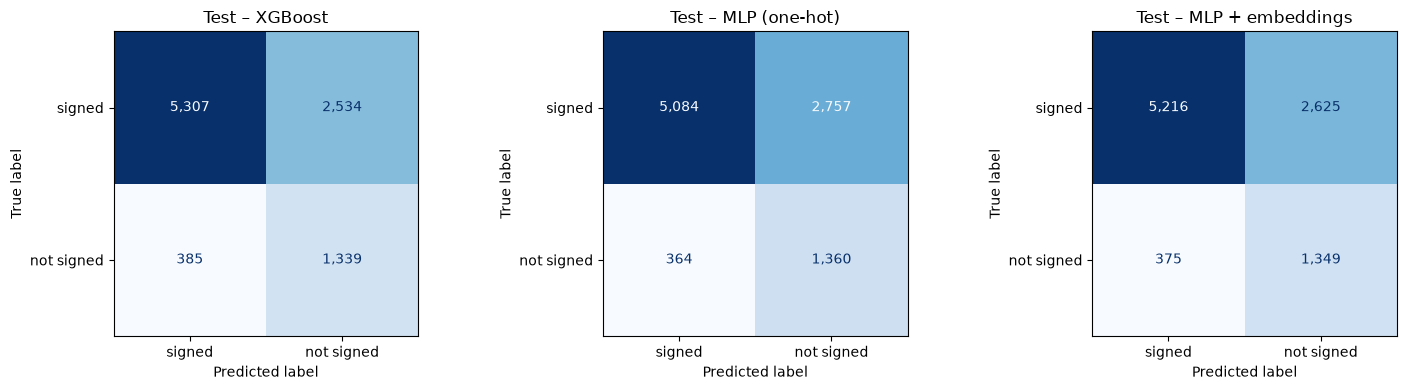

In [68]:
test_cmp = comparison.xs("test", level="Set")[["Accuracy", "Balanced acc.", "Precision", "Recall", "F1",
                                               "ROC AUC", "PR AUC"]]
ax = test_cmp.T.plot(kind="bar", figsize=(14, 5), width=0.8)
ax.set_title("Test set performance (positive class = not signed, threshold 0.5)")
ax.set_ylim(0, 1)
ax.legend(loc="upper left", ncols=4)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
for name, p in models.items():
    yt, pr = p["test"]
    if name == "Majority baseline":
        continue
    fpr, tpr, _ = roc_curve(yt, pr)
    axes[0].plot(fpr, tpr, label=f"{name} (AUC = {roc_auc_score(yt, pr):.3f})")
    prec, rec, _ = precision_recall_curve(yt, pr)
    axes[1].plot(rec, prec, label=f"{name} (AP = {average_precision_score(yt, pr):.3f})")
axes[0].plot([0, 1], [0, 1], "k--", label="random / majority baseline")
axes[0].set(xlabel="False positive rate", ylabel="True positive rate", title="ROC curves (test)")
axes[1].axhline(y_te.mean(), color="k", ls="--", label=f"baseline (prevalence = {y_te.mean():.3f})")
axes[1].set(xlabel="Recall", ylabel="Precision", title="Precision–recall curves (test)")
axes[0].legend(loc="lower right"); axes[1].legend(loc="upper right")
plt.tight_layout()
plt.show()

plot_confusions({n: models[n]["test"] for n in ["XGBoost", "MLP (one-hot)", "MLP + embeddings"]}, "Test")

## Decision threshold and uncertainty of the results

With class weighting the default threshold 0.5 favours recall. If the goal is the best F1 of the "not signed" class,
the threshold can be tuned on the **validation** set and then applied to the test set. The 95 % confidence intervals
of the test metrics are estimated with 1 000 bootstrap resamples of the test set.

In [69]:
def best_threshold(yt, p):
    prec, rec, thr = precision_recall_curve(yt, p)
    f1 = 2 * prec * rec / np.clip(prec + rec, 1e-12, None)
    return thr[np.argmax(f1[:-1])]


rng = np.random.default_rng(RANDOM_STATE)
boot_idx = [rng.integers(0, len(y_te), len(y_te)) for _ in range(1000)]

rows = []
for name in ["XGBoost", "MLP (one-hot)", "MLP + embeddings"]:
    p = models[name]
    thr = best_threshold(*p["validation"])
    yt, pt = p["test"]
    auc_b = [roc_auc_score(yt[b], pt[b]) for b in boot_idx]
    f1_b = [f1_score(yt[b], pt[b] >= 0.5) for b in boot_idx]
    tuned = scores(yt, pt, thr)
    rows.append({"Model": name,
                 "Test ROC AUC": roc_auc_score(yt, pt),
                 "AUC 95% CI": f"[{np.percentile(auc_b, 2.5):.3f}, {np.percentile(auc_b, 97.5):.3f}]",
                 "Test F1 @0.5": f1_score(yt, pt >= 0.5),
                 "F1 95% CI": f"[{np.percentile(f1_b, 2.5):.3f}, {np.percentile(f1_b, 97.5):.3f}]",
                 "Tuned threshold": thr, "Test F1 @tuned": tuned["F1"],
                 "Precision @tuned": tuned["Precision"], "Recall @tuned": tuned["Recall"],
                 "Accuracy @tuned": tuned["Accuracy"],
                 "Train-test AUC gap": roc_auc_score(*p["train"]) - roc_auc_score(yt, pt)})
final = pd.DataFrame(rows).set_index("Model")
final.round(4)

,Test ROC AUC,AUC 95% CI,Test F1 @0.5,F1 95% CI,Tuned threshold,Test F1 @tuned,Precision @tuned,Recall @tuned,Accuracy @tuned,Train-test AUC gap
Model,,,,,,,,,,
XGBoost,0.7999,"[0.789, 0.810]",0.4785,"[0.462, 0.494]",0.5683,0.4943,0.3798,0.7077,0.7390,0.0277
MLP (one-hot),0.7909,"[0.779, 0.802]",0.4657,"[0.450, 0.481]",0.6039,0.4821,0.3691,0.6949,0.7309,0.0250
MLP + embeddings,0.7922,"[0.781, 0.803]",0.4735,"[0.457, 0.489]",0.6004,0.4891,0.3838,0.6740,0.7462,0.0283


# Conclusions

1. **Data.** The three tables of the LAMA BPO admission dataset were downloaded from data.gov.lt, cleaned
   (data types, municipality names unified, municipality → county mapping added, technical and leaking columns removed,
   outliers clipped / log-transformed) and joined into **47 826 invitations** described by 29 features. The main data problem
   is faulty pseudonymisation of applicants in `Prasymas`: there are ≈ 1.7 ids per real applicant (42 122 ids in the
   2024 main round vs. 24 548 official applicants) and most choice lists are incomplete, i.e. one person's choices are
   split over several ids. As a result only ≈ 11 % of invitations could be linked to an applicant profile, and the
   applicant features had to be derived from these fragments.

2. **Hypothesis 1 – confirmed.** Applicants invited to a priority 1–2 programme sign more often than those invited to
   priority 3–9 (84.1 % vs. 73.0 %), and applicants invited to a state-funded place sign much more often than to a self-paid
   place (91.0 % vs. 69.6 %). Both differences are statistically significant (p < 0.001). Funding type is also the most
   important feature of the XGBoost model (43 % of the total gain), followed by the institution (14 %), the study field group (8 %),
   the county of studies and the study type.

3. **Hypothesis 2 – partly confirmed.** Invitations in the main round are signed more often than in the additional rounds
   (83.9 % vs. 71.7 %, p < 0.001). However, studying in the **home municipality or county makes no difference**
   (82.3 % vs. 81.6 %, p = 0.58; 81.5 % vs. 82.2 %, p = 0.53). This part could only be tested on the 5 021 invitations with
   a known place of residence.

4. **Hypothesis 3 – confirmed for ROC AUC and F1, not for accuracy.** All models are clearly better than the
   majority-class baseline in the chosen metrics: test ROC AUC 0.79–0.80 vs. 0.50 and F1 of the "not signed" class
   0.47–0.48 vs. 0. At threshold 0.5 the class-weighted models find ≈ 78 % of applicants who will not sign, with precision 33–35 %.
   Their accuracy (0.67–0.69, or 0.73–0.75 with the tuned threshold) is **lower** than the 82 % of the baseline, because the
   models deliberately trade accuracy for finding the minority class. With such class imbalance, accuracy is not a suitable measure.

5. **Comparison of the best models (test set).**

   | Model | ROC AUC (95 % CI) | PR AUC | F1 @0.5 | Recall | Precision | Train–test AUC gap |
   |---|---|---|---|---|---|---|
   | XGBoost (lr 0.03, depth 5, 300 trees, min_child_weight 50, subsample 0.8) | **0.800** (0.789–0.810) | **0.461** | **0.479** | 0.777 | 0.346 | 0.028 |
   | MLP + embeddings (emb. size 2, 256-128, L2 1e-3, lr 3e-4) | 0.792 (0.781–0.803) | 0.443 | 0.474 | 0.783 | 0.340 | 0.028 |
   | MLP one-hot (3 × 256, ReLU, RMSprop, lr 1e-4, batch 64) | 0.791 (0.779–0.802) | 0.444 | 0.466 | 0.789 | 0.330 | 0.025 |
   | Majority baseline | 0.500 | 0.180 | 0.000 | 0.000 | – | – |

   **XGBoost is the best model** in all ranking metrics, and it also trains fastest (~1.5 s vs. 10–30 s per network) and is the
   easiest to interpret. The differences between the three models are small (the confidence intervals overlap). Embeddings
   improved the MLP only slightly, because the programme identity adds little to the programme features already included.
   After tuning, none of the models over-fits much: the train–test AUC gap is ≈ 0.03, compared to a train–validation gap of 0.095 for the
   default XGBoost. Choosing the decision threshold on the validation set raises the test F1 to 0.48–0.49 (XGBoost: 0.494).

6. **Limitations and possible improvements.** The models reach an AUC of about 0.80 whatever their parameters, so the
   limit comes from the available information: the dataset has no admission scores, no information about the applicant's
   competing offers, profile data is missing for 89 % of invitations, and the applicant's choice list is split over several ids.
   Consistent applicant ids (the problem can be reported to the data provider, atverimas@stat.gov.lt) – giving complete
   choice lists and profiles for everyone – and adding competition scores would probably
   help more than further model tuning.